### Top

In [1]:
from volta.prelude import *
import sys
from volta.plotting import *
from volta.test_objects import *
np.set_printoptions(precision=5, suppress=True)

meshcat = StartMeshcat()
port = str(meshcat.web_url())[-4:]
print(f"Sharing URL: tanawatp@tanawat-ROG.local:{port}")
print(f"Download URL: {meshcat.web_url()}/download")

/home/tanawatp/volta_env/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
INFO:drake:Meshcat listening for connections at http://localhost:7000


Sharing URL: tanawatp@tanawat-ROG.local:7000
Download URL: http://localhost:7000/download


### Simulation parameters

In [2]:
save_graph          = False
fixed_base          = False
gravity_enable      = True
force_viz           = False
enable_gait_planner = False
enable_noise        = True

In [3]:
# --- Experiment configulation ---
exp_id = "0a"
exp_config = GetConfigByName(exp_id)
exp_config.DisplayConfig()
# Simulation configulation
sim_time_step = exp_config.sim_timestep    # [second]
dt = 0.01  # [second] MPC update time

fixed_base_offset = 0.5 # [m] offset for fixed base

gravity = [0, 0, -9.81*gravity_enable]

# Simulation time
sim_time= exp_config.sim_time# [second]
# sim_time = 0.001
# Robot configulation
set_initial_pose_by = "c" # q: joint position, c: CoM position, h: torso position
model_name = "Volta_rev5"
# Ploting configulation
plot_interval = (0.005, sim_time) # [second] time interval for plotting

if save_graph:
    if enable_noise:
        save_path = f"{RESULT_ROOT}/Final/Pics/{exp_config.exp_name}_noise"
    else:
        save_path = f"{RESULT_ROOT}/Final/Pics/{exp_config.exp_name}"
else:
    save_path = None


Experiment Name: exp_0a_stablization
Profile Type: 0
Floor Stiffness: 5e+06
Dissipation: 50.0
Joint Damping: 0.3
Noise Std Dev: 0.0
Simulation Time: 3.0
Simulation Time Step: 0.0001


In [4]:
plant_fixed_base:MultibodyPlant
plant_fixed_base,dump = DefinePlant(model_name=model_name,
                            is_fixed=True,
                            fixed_frame="torso")
plant_fixed_base_context = plant_fixed_base.CreateDefaultContext()
match set_initial_pose_by:
    case "q":
        left_q = np.zeros(6)
        right_q = np.zeros(6)
        torso_positions = CalcForwardKinematics(plant=plant_fixed_base,
                                    generalize_positions=np.concatenate((left_q, right_q)),
                                    base_frame_name="L_foot_contact",
                                    end_effector_frame_name="torso")
        print(f"Torso height: {torso_positions[2]} m")
        init_pos = [0.0 ,0.0, torso_positions[2]+(fixed_base_offset*fixed_base)] # body frame position [m] from world frame
        q = np.concatenate((left_q, right_q))
    case "h":
        desire_torso_height = 0.4 # [m] desired torso height
        is_success,left_q = SolveInverseKinematics(model_series="Volta",
                                    plant=plant_fixed_base,
                                    is_left=True,
                                    base_P_e=np.array([0.0,0.125,-1.0*desire_torso_height]),
                                    base_R_e=RollPitchYaw(0, 0, 0).ToRotationMatrix())
        is_success,right_q = SolveInverseKinematics(model_series="Volta",
                                    plant=plant_fixed_base,
                                    is_left=False,
                                    base_P_e=np.array([0.0,-0.125,-1.0*desire_torso_height]),
                                    base_R_e=RollPitchYaw(0, 0, 0).ToRotationMatrix())
        init_pos = [0.0, 0.0,desire_torso_height+(fixed_base_offset*fixed_base)]
        q = np.concatenate((left_q, right_q))
        com_high = 0.22
    case "c":
        com_high = 0.35
        is_success,q = SolveIKWithComPositionConstraint(model_series="Volta",
                                                        plant=plant_fixed_base,
                                                        is_L_stance=True,
                                                        st_P_com=np.array([0.0, -0.125, com_high]),
                                                        st_R_base=RotationMatrix.Identity(),
                                                        st_P_sw=np.array([0.0, -0.25, 0.0]),
                                                        st_R_sw=RotationMatrix.Identity())
        torso_positions = CalcForwardKinematics(plant=plant_fixed_base,
                                            generalize_positions=q,
                                            base_frame_name="L_foot_contact",
                                            end_effector_frame_name="torso")
        # print("torso_positions",torso_positions)
        init_pos = [torso_positions[0] ,torso_positions[1]+0.125, torso_positions[2]+(fixed_base_offset*fixed_base)]
        print(torso_positions)
        # print(q)
init_orien = np.asarray([0, 0, 0]) # body fram orientation [degree] rotate xyz fixed axis
left_qd = np.zeros(6)
right_qd = np.zeros(6)

[-0.03296 -0.125    0.49439]


### Create multibody plant and diagram

In [5]:
def FootstepsViz(meshcat, footstep_plan, alpha=0.5, z_offset=0.002):
    """
    Visualizes a list of footsteps in Meshcat.
    
    Args:
        meshcat: The Meshcat instance.
        footstep_plan: List of dicts with 'index', 'pos', 'ang', and 'foot_id'.
        alpha: Transparency value (0.0 to 1.0).
        z_offset: Tiny height increase to prevent flickering (Z-fighting).
    """
    # Foot dimensions (Length x Width x Thickness)
    foot_length = 0.23
    foot_width = 0.11
    foot_thickness = 0.002
    
    # Define colors with the requested transparency
    color_left = Rgba(1, 0, 0, alpha)   # Red
    color_right = Rgba(0, 0, 1, alpha)  # Blue

    for step in footstep_plan:
        # Create a unique path for each step in the Meshcat tree
        path = f"footstep_plan/step_{step['index']}"
        
        # Select color based on the foot_id
        color = color_left if step['foot_id'] == 'lfoot' else color_right
        
        # 1. Set the geometry (The box shape)
        meshcat.SetObject(path, Box(foot_length, foot_width, foot_thickness), color)
        
        # 2. Set the transform (Position + Rotation)
        # We add the z_offset to the z-coordinate of the position
        pose = RigidTransform(
            RollPitchYaw(step['ang']), 
            step['pos'] + np.array([0, 0, z_offset])
        )
        
        meshcat.SetTransform(path, pose)

In [6]:
params = {
'g': 9.81,
'h': com_high,
'foot_size': 0.08,
'step_height': 0.03,
'ss_duration': 70,
'ds_duration': 30, 
'mpc_time_step': 0.01,
'first_swing': 'rfoot',
'first_stance': 'lfoot',
'N': 100,
}
params['eta'] = np.sqrt(params['g'] / params['h'])
initial = {
       'lfoot': {'pos': np.array([0,0,0,0,0.125,0]),
                     'vel': np.zeros(6),
                     'acc': np.zeros(6)},
       'rfoot': {'pos': np.array([0,0,0,0,-0.125,0]),
                     'vel': np.zeros(6),
                     'acc': np.zeros(6)},
       'com'  : {'pos': np.array([0,0,com_high]),
                     'vel': np.zeros(6),
                     'acc': np.zeros(3)},
       'zmp'  : {'pos': np.zeros(3),
                     'vel': np.zeros(3),
                     'acc': np.zeros(3)}
       }
desired = copy.deepcopy(initial)
current = copy.deepcopy(initial)
# footsteps_planner = FootstepsPlanner()
planner = FootstepsPlanner(params=params)
initial_pos = [0.0,0.125,0.0]
plan = planner.PlanFootsteps(initial_pos, exp_config.VRefCommand, np.clip(sim_time-2.0,min=1.0), params['first_stance'])
# planner.PlotFootsteps(steps=plan,initial_pose=initial_pos,v_ref_func=exp_config.VRefCommand)
meshcat.Delete()
meshcat.DeleteAddedControls()

if exp_id == "4a":
    FootstepsViz(meshcat, plan, alpha=0.3, z_offset=0.0085)
    temp0 = RigidTransform(
    RollPitchYaw([0,0,0]), p=[0.0,0,0.05])
else:
    FootstepsViz(meshcat, plan, alpha=0.3, z_offset=0.0001)
    temp0 = RigidTransform(
    RollPitchYaw([0,0,0]), p=[0.0,0,0.00])

dir = "/home/tanawatp/Documents/Thesis_simulation/Models"

builder = DiagramBuilder()
plant, scene_graph = AddMultibodyPlantSceneGraph(
    builder, time_step=sim_time_step)
plant:MultibodyPlant = plant
parser = Parser(plant)

# Set the gravity feild
plant.mutable_gravity_field().set_gravity_vector(gravity)

# Add models to multibody plant
robot_instant_index = parser.AddModelsFromString(exp_config.robot_urdf, "urdf")

if exp_config.multi_terrain:
    floor        = parser.AddModelsFromString(exp_config.multi_terrain_sdf, "sdf")
    floor_frame = plant.GetFrameByName(f"floor_0_frame")
else:
    floor               = parser.AddModelsFromString(exp_config.floor_sdf, "sdf")
    floor_frame = plant.GetFrameByName("floor_top_center")


plant.WeldFrames(plant.world_frame(), 
                floor_frame,
                temp0)
X_floorRobot = RigidTransform(
    RollPitchYaw(init_orien * np.pi / 180), p=init_pos)
if fixed_base:
    robot_body_frame = plant.GetFrameByName("torso")
    plant.WeldFrames(plant.world_frame(),robot_body_frame, X_floorRobot)
    print("Simulation in Fixed based mode")
else:
    print("Simulation in Folating based mode")
plant.Finalize()

# Set initial pose of robot
plant_context = plant.CreateDefaultContext()
robot = plant.GetBodyByName("torso")
X_Worldfloor = floor_frame.CalcPoseInWorld(plant_context) 

X_WorldRobot = X_Worldfloor.multiply(X_floorRobot)
plant.SetDefaultFloatingBaseBodyPose(robot, X_WorldRobot)

vis_config = VisualizationConfig()

# 2. Explicitly turn off contact force visualization
vis_config.publish_contacts = force_viz
# Disable Meshcat mouse spring: it claims applied_spatial_force, which the pusher needs
vis_config.mouse_interaction_stiffness = None
ApplyVisualizationConfig(vis_config, builder, meshcat=meshcat)


Simulation in Folating based mode


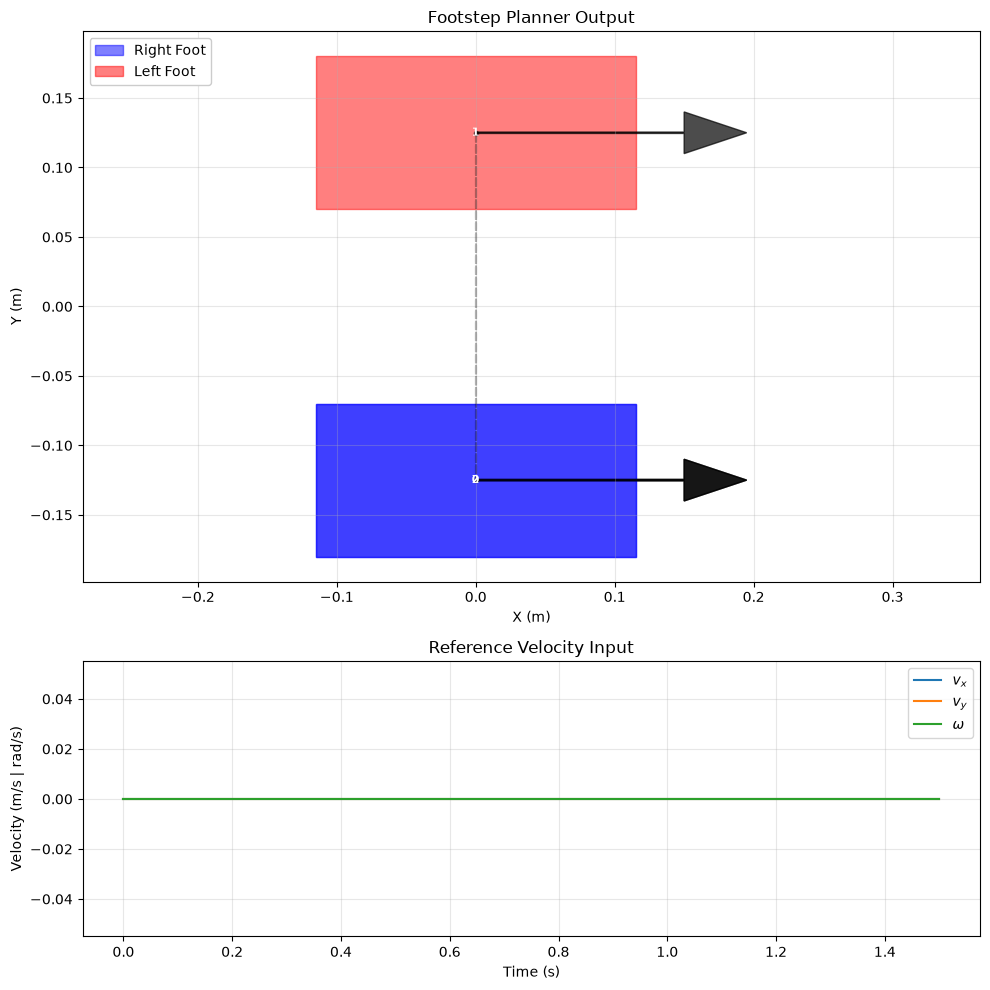

In [7]:
planner.PlotFootsteps(steps=plan,initial_pose=initial_pos,v_ref_func=exp_config.VRefCommand)

### Add and connect system 

In [8]:
contact_force_sensor = builder.AddNamedSystem("Contact force sensor",
                                            ContactForceSensor(dt=0.01,plant=plant))
plant_floating_base,dump = DefinePlant(model_name=model_name,
                                          is_fixed=False,
                                          fixed_frame=None)
walk_recorder = builder.AddNamedSystem("Walk_recorder",
                                    WalkRecorder(meshcat=meshcat,
                                                 plant=plant,
                                                 context=plant_context,
                                                 model_instances=robot_instant_index))

gait_planner = builder.AddNamedSystem("ISMPC",
                                          GaitPlanner(
                                                      plant=plant_floating_base,
                                                      footsteps_planner=planner,
                                                      initial_states=initial,
                                                      params=params,
                                                      enable=enable_gait_planner)
                                          )

passivity_based_WBC = builder.AddNamedSystem("Passivity based WBC",
                            PassivityBasedWBC2(plant=plant_floating_base,
                                                 CoM_kp           = np.ones(3)*3000.0,
                                                 CoM_kd           = np.ones(3)*300.0,
                                                 CoM_k_stiffness  = np.ones(3)*20.0,   
                                                 CoM_k_damping    = np.ones(3)*1.5,      
                                                 sw_kp            = np.ones(3)*400.0,
                                                 sw_kd            = np.ones(3)*20.0,
                                                 sw_k_stiffness   = np.ones(3)*10.0,
                                                 sw_k_damping     = np.ones(3)*0.7,
                                                 initial_joint_position=q,
                                                 dt=0.001))
taskspace_feedback = builder.AddNamedSystem("Taskspace feedback",
                                            TaskSpaceFeedback(plant=plant_floating_base))
ground_truth_taskspace_feedback = builder.AddNamedSystem("Groundtruth taskspace feedback",
                                            TaskSpaceFeedback(plant=plant_floating_base))
if enable_noise:
    state_noiser = builder.AddSystem(RobotStateNoiseGenerator(
        num_joints=12,
        q_base_ori_sig=0.00,    # Clean orientation for now
        q_base_pos_sig=0.003,
        q_joint_sig=0.0001,
        v_base_ang_sig=0.00,
        v_base_lin_sig=0.005,
        v_joint_sig=0.005
    ))
else:
    state_noiser = builder.AddSystem(RobotStateNoiseGenerator(
        num_joints=12,
        q_base_ori_sig=0.00,    # Clean orientation for now
        q_base_pos_sig=0.00,
        q_joint_sig=0.00,
        v_base_ang_sig=0.00,
        v_base_lin_sig=0.00,
        v_joint_sig=0.00
    ))
zmp_buffer = builder.AddSystem(ZeroOrderHold(period_sec=0.001, vector_size=3))

states_estimator = builder.AddNamedSystem(
    "state estimator",
    StateEstimator(dt=0.001, initial=initial, mpc=gait_planner.mpc)
)

pusher = builder.AddSystem(DisturbanceGenerator(
    plant, 
    body_name="torso", 
    force_xyz=exp_config.forces, 
    tau=exp_config.tau,
    start_time=exp_config.apply_wrenches_t, 
    duration=0.2,
    meshcat=meshcat
))



### Wiring the systems

In [9]:


# 2. Wire CLEAN state into the Noiser
builder.Connect(
    plant.get_state_output_port(robot_instant_index[0]),
    state_noiser.get_input_port(0)
)
noisy_state_port = state_noiser.get_output_port(0)

# --- REWIRED ESTIMATION LOOP ---

# A. Taskspace Feedback (Calculates RAW CoM from noisy state)
builder.Connect(noisy_state_port, taskspace_feedback.get_input_port(0))
builder.Connect(plant.get_state_output_port(robot_instant_index[0]), ground_truth_taskspace_feedback.get_input_port(0))

# B. Contact Force Sensor (Calculates RAW ZMP from noisy state)
builder.Connect(plant.get_contact_results_output_port(), contact_force_sensor.get_input_port(0))
builder.Connect(noisy_state_port, contact_force_sensor.get_input_port(1))

# C. Feed the Estimator (Inputs: CoM, ZMP, Desired ZMP)
builder.Connect(taskspace_feedback.get_output_port(0), states_estimator.get_input_port(0)) # Port 0: CoM
builder.Connect(contact_force_sensor.get_output_port(1), states_estimator.get_input_port(1)) # Port 1: Meas ZMP
# 2. Connect Planner -> Buffer -> Estimator
builder.Connect(gait_planner.get_output_port(5), zmp_buffer.get_input_port())
builder.Connect(zmp_buffer.get_output_port(), states_estimator.get_input_port(2))

# --- REWIRED DOWNSTREAM CONNECTIONS ---

# Gait Planner (Uses noisy state for general pose, but FILTERED ZMP for planning)
builder.Connect(states_estimator.get_output_port(0), gait_planner.get_input_port(0))
builder.Connect(states_estimator.get_output_port(1), gait_planner.get_input_port(1)) # Port 1: Filtered ZMP

# Passivity-based WBC 
builder.Connect(noisy_state_port, passivity_based_WBC.get_input_port(0)) # General state

# Connect Gait Planner outputs to WBC (Port 1 to 4)
for port_idx in range(4):
    builder.Connect(gait_planner.get_output_port(port_idx), 
                    passivity_based_WBC.get_input_port(port_idx+1))

# Connect Taskspace/Estimator outputs to WBC
# We use FILTERED CoM for port 5 instead of raw taskspace feedback
builder.Connect(states_estimator.get_output_port(0), passivity_based_WBC.get_input_port(5)) 

# Remaining Taskspace Feedback (Ports 6-7: e.g., Swing foot tasks)
for port_idx in [1, 2]:
    builder.Connect(taskspace_feedback.get_output_port(port_idx), 
                    passivity_based_WBC.get_input_port(port_idx+5))

# Final Force Sensor and Actuation
builder.Connect(contact_force_sensor.get_output_port(2), passivity_based_WBC.get_input_port(8))
builder.Connect(passivity_based_WBC.get_output_port(0), plant.get_actuation_input_port(robot_instant_index[0]))

builder.Connect(
    pusher.get_output_port(),
    plant.get_applied_spatial_force_input_port()
)

builder.Connect(
    plant.get_body_poses_output_port(),
    pusher.get_input_port()
)

## Loggers

In [10]:
[torque_command_logger, 
    desired_foot_wrenchs_logger, 
    fz_boundaries_logger,
    walking_phase_logger]  = CreateLoggers(builder=builder,
                                            system= passivity_based_WBC,
                                            port_num=[0,1,2,3],
                                            name=["torque_command_logger",
                                                    "desired_foot_wrenchs_logger",
                                                    "fz_boundaries_logger",
                                                    "walking_phase_logger"])
[CoM_state_logger,
    lfoot_state_logger,
    rfoot_state_logger] = CreateLoggers(builder=builder,
                                    system=taskspace_feedback,
                                    port_num=[0,1,2],
                                    name=["CoM_statelogger",
                                            "lfoot_state_logger",
                                            "rfoot_state_logger"])
[filtered_CoM_state_logger,
filtered_ZMP_logger] = CreateLoggers(builder=builder,
                                    system=states_estimator,
                                    port_num=[0,1],
                                    name=["filtered_CoM_state_logger",
                                            "filtered_ZMP_logger"])

[groundtruth_CoM_state_logger] = CreateLoggers(builder=builder,
                                    system=ground_truth_taskspace_feedback,
                                    port_num=[0],
                                    name=["groundtruth_CoM_state_logger"])
[GRF_logger,
ZMP_logger,
ZMP_in_foot_frame_logger,
total_contact_wrenches_logger] = CreateLoggers(builder=builder,
                                    system=contact_force_sensor,
                                    port_num=[0,1,2,3],
                                    name=["GRF_logger",
                                            "ZMP_logger",
                                            "ZMP_in_foot_frame_logger",
                                            "total_contact_wrenches_logger"])
[COM_traj_logger,
    L_foot_traj_logger,
    R_foot_traj_logger,
    contact_logger,
    desired_zmp_logger] = CreateLoggers(builder=builder,
                                    system=gait_planner,
                                    port_num=[0,1,2,3,4],
                                    name=["COM_traj_logger",
                                            "L_foot_traj_logger",
                                            "R_foot_traj_logger",
                                            "contact_logger",
                                            "desired_zmp_logger"])
net_torque_logger = LogVectorOutput(plant.get_net_actuation_output_port(robot_instant_index[0]), builder)
net_torque_logger.set_name("net_torque_logger")

## Add visualization

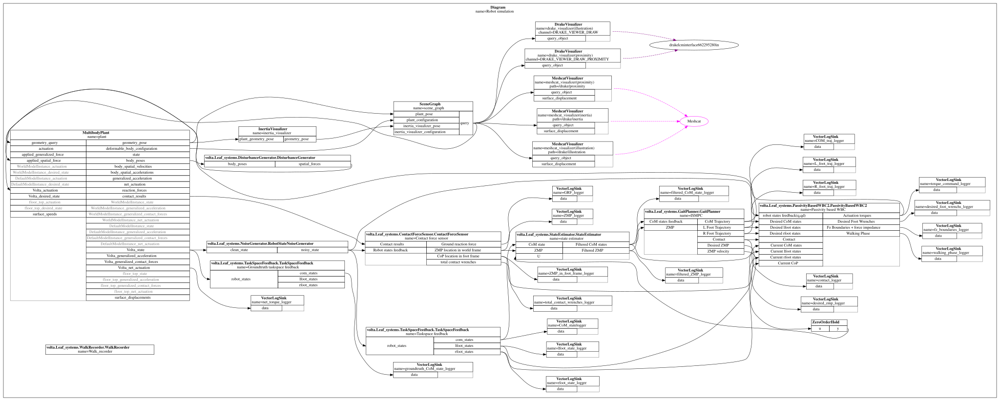

In [11]:
# AddDefaultVisualization(builder=builder, meshcat=meshcat)
diagram = builder.Build()
diagram.set_name("Robot simulation")
show_diagram(diagram=diagram,show=True,hide_loggers=False)

# Exicute simulation

In [12]:
simulator = Simulator(diagram)
new_context = diagram.CreateDefaultContext()
simulator.reset_context(new_context)
context = simulator.get_mutable_context()

plant_context = plant.GetMyContextFromRoot(context)
walk_recorder.root_context = context
num_positions = plant.num_positions(robot_instant_index[0])  # Get the total number of positions in the plant

body_quanternion_wxyz = [1.0, 0.0, 0.0, 0.0]
body_pose = np.concatenate((np.array([body_quanternion_wxyz]), np.array([init_pos])), axis=1)
initial_joint_positions = np.array([q])
initial_joint_velocities = np.concatenate((np.array([left_qd]), np.array([right_qd])), axis=1)
if fixed_base:
    initial_generalize_positions = initial_joint_positions[0] # fixed base
    initial_generalize_velocity = initial_joint_velocities[0]
else:
    initial_generalize_positions = np.concatenate((body_pose, initial_joint_positions),axis=1)[0] # floating base
    initial_generalize_velocity = np.concatenate((np.zeros([1,6]), initial_joint_velocities),axis=1)[0]

plant.SetPositions(plant_context, robot_instant_index[0], initial_generalize_positions)
# plant.SetVelocities(plant_context, robot_instant_index[0], initial_qd)

simulator.Initialize()
simulator.set_target_realtime_rate(0.15)
meshcat.StartRecording()
# try:
simulator.AdvanceTo(sim_time)
# except Exception as e:
#     print("Simulation error:", e)
meshcat.PublishRecording()

# Plot

In [13]:
# Taskspace feedback logs
com_state_log               = CoM_state_logger.FindLog(context)
lfoot_state_log             = lfoot_state_logger.FindLog(context)
rfoot_state_log             = rfoot_state_logger.FindLog(context)
actual_CoM_state_data       = com_state_log.data()
actual_lfoot_state_data     = lfoot_state_log.data()
actual_rfoot_state_data     = rfoot_state_log.data()
time                        = com_state_log.sample_times()
# Groundtruth 
groundtruth_CoM_state_data = groundtruth_CoM_state_logger.FindLog(context).data()
# State Estimator
filtered_CoM_state_data     = filtered_CoM_state_logger.FindLog(context).data()
filtered_ZMP_data           = filtered_ZMP_logger.FindLog(context).data()
# Contact Force Sensor logs
GRF_log                     = GRF_logger.FindLog(context)
ZMP_log                     = ZMP_logger.FindLog(context)
ZMP_in_foot_frame_log       = ZMP_in_foot_frame_logger.FindLog(context)
total_contact_wrenches_log  = total_contact_wrenches_logger.FindLog(context)
GRF_data                    = GRF_log.data()
actual_ZMP_data             = ZMP_log.data()
ZMP_in_foot_frame_data      = ZMP_in_foot_frame_log.data()
total_contact_wrenches_data = total_contact_wrenches_log.data()
# Gait Planner logs
COM_traj_log        = COM_traj_logger.FindLog(context)
L_foot_traj_log     = L_foot_traj_logger.FindLog(context)
R_foot_traj_log     = R_foot_traj_logger.FindLog(context)
contact_log         = contact_logger.FindLog(context)
desired_zmp_log     = desired_zmp_logger.FindLog(context)
desired_CoM_state_data      = COM_traj_log.data()
desired_lfoot_state_data    = L_foot_traj_log.data()
desired_rfoot_state_data    = R_foot_traj_log.data()
contact_data        = contact_log.data()
desired_zmp_data    = desired_zmp_log.data()
# WBC
torque_command_log          = torque_command_logger.FindLog(context)
desired_foot_wrenchs_log    =  desired_foot_wrenchs_logger.FindLog(context)
fz_boundaries_log           = fz_boundaries_logger.FindLog(context)
walking_phase_log           = walking_phase_logger.FindLog(context)
torque_command_data         = torque_command_log.data()
desired_foot_wrenchs_data   = desired_foot_wrenchs_log.data()
# actual torque
net_torque_log              = net_torque_logger.FindLog(context)
net_torque_data             = net_torque_log.data()


In [14]:
initial_generalize_positions

array([ 1.     ,  0.     ,  0.     ,  0.     , -0.03296, -0.     ,
        0.49439, -0.62451,  0.     ,  0.     , -1.39231, -0.76748,
        0.     ,  0.62477,  0.     ,  0.     ,  1.39281,  0.76766,
        0.     ])

In [15]:
actual_lfoot_state_data[3:6,3]

array([0.0001 , 0.1246 , 0.00287])

In [16]:
actual_rfoot_state_data[3:6,3]

array([ 0.00019, -0.12538,  0.00291])

In [17]:
plant.GetPositions(plant_context, robot_instant_index[0])

array([ 1.     ,  0.00016, -0.00169,  0.00065, -0.03279,  0.0003 ,
        0.49433, -0.62113, -0.00167,  0.00044, -1.39243, -0.76762,
       -0.00081,  0.62003, -0.00291,  0.00484,  1.39324,  0.76954,
        0.00074])

In [18]:
filtered_ZMP_data[:,3]

array([0.00002, 0.00002, 0.     ])

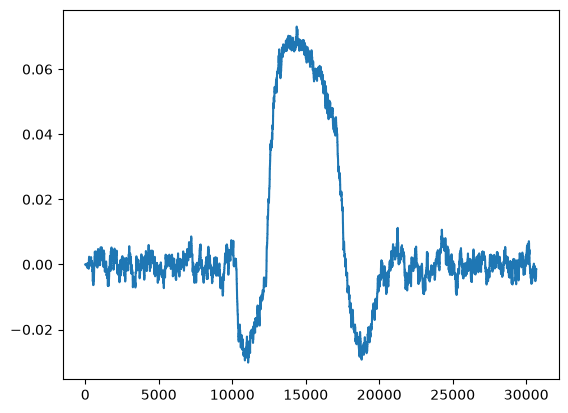

In [19]:
plt.plot(filtered_ZMP_data[0,:], label="Filtered ZMP")

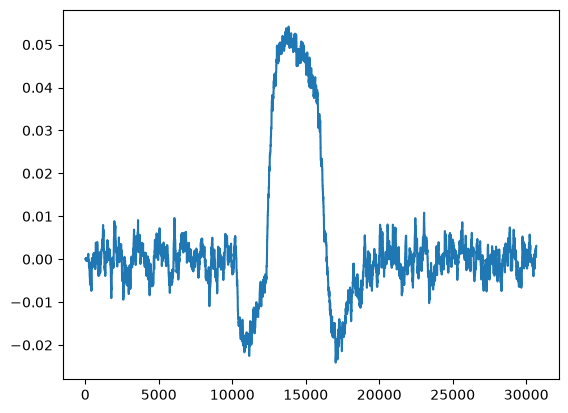

In [20]:
plt.plot(filtered_ZMP_data[1,:], label="Filtered ZMP")

In [21]:
# 1. Define folder and file names
folder_name = f"{RESULT_ROOT}/Final/Data"
if enable_noise:
    file_name = f"{exp_config.exp_name[0:6]}_noise.npz"
else:
    file_name = f"{exp_config.exp_name[0:6]}.npz"
os.makedirs(folder_name, exist_ok=True)

# 3. Construct the full path (e.g., 'data_logs/experiment_01.npz')
full_path = os.path.join(folder_name, file_name)
# 2. Save all variables into one compressed archive
walking_phase = []
for i in range(contact_data.shape[1]):
    if contact_data[0, i] == 1 and contact_data[1, i] == 0:
        walking_phase.append(0)
    elif contact_data[0, i] == 0 and contact_data[1, i] == 1:
        walking_phase.append(1)
    elif contact_data[0, i] == 1 and contact_data[1, i] == 1:
        walking_phase.append(2)
walking_phase = np.array(walking_phase)
# format: key_name = variable_name
if save_graph:
    print(f"Saving data to: {full_path}")
    np.savez_compressed(
        full_path,
        timestamp       = time,
        desired_zmp     = desired_zmp_data,
        desired_com     = desired_CoM_state_data,
        desired_lfoot   = desired_lfoot_state_data,
        desired_rfoot   = desired_rfoot_state_data,
        walking_phase   = walking_phase,
        raw_ZMP         = actual_ZMP_data,
        raw_com         = actual_CoM_state_data,
        raw_lfoot       = actual_lfoot_state_data,
        raw_rfoot       = actual_rfoot_state_data,
        groundtruth_CoM = groundtruth_CoM_state_data,
        filtered_CoM    = filtered_CoM_state_data,
        filtered_ZMP    = filtered_ZMP_data,
        GRF             = GRF_data,
        torque_command  = torque_command_data,
        desired_foot_wrenches = desired_foot_wrenchs_data,
    )


NameError: name 'RESULT_ROOT' is not defined

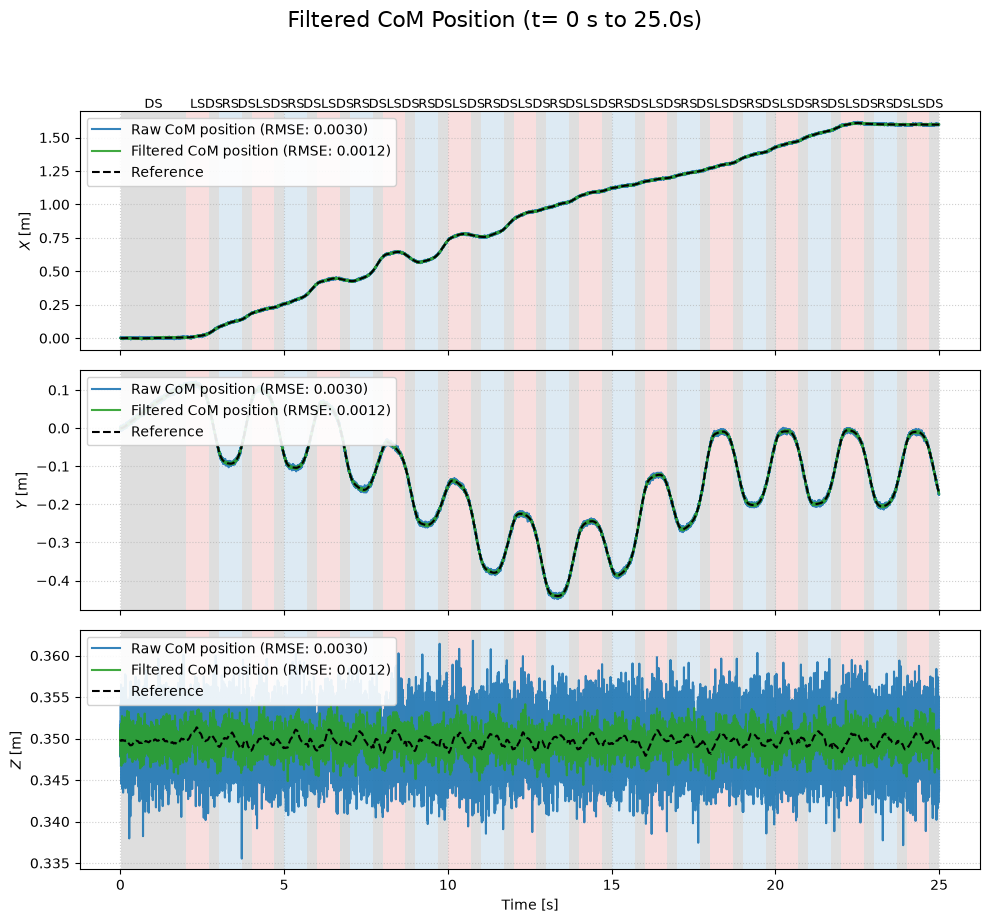

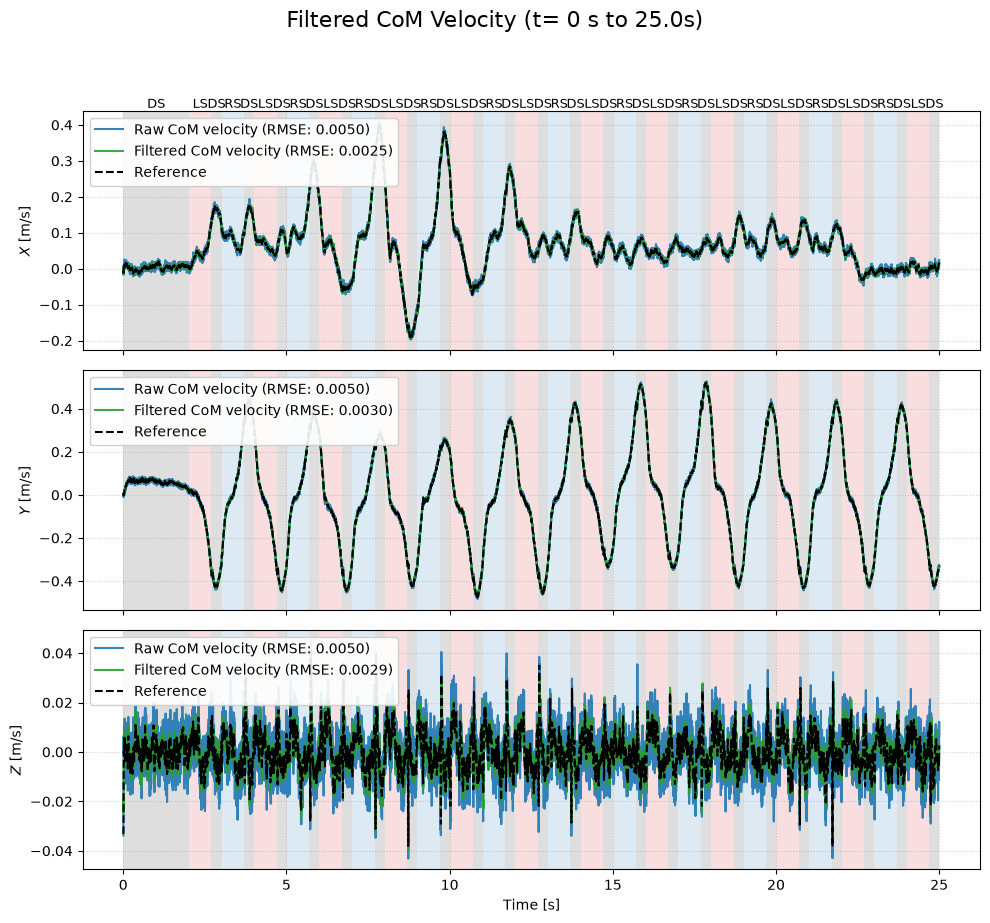

In [ ]:
PlotTrackingCompare(
    time_log=time[::10], 
    ref_data=groundtruth_CoM_state_data[3:6,::10], 
    act_data=[actual_CoM_state_data[3:6,::10],filtered_CoM_state_data[3:6,::10]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=walking_phase[::10], 
    act_labels=["Raw CoM position","Filtered CoM position"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['X', 'Y', 'Z'], 
    unit='m',
    title="Filtered CoM Position",
    plot_interval=plot_interval,
    show_error=False,
    save_folder=save_path,
    show_plot = True
)
PlotTrackingCompare(
    time_log=time[::10], 
    ref_data=groundtruth_CoM_state_data[9:12,::10], 
    act_data=[actual_CoM_state_data[9:12,::10],filtered_CoM_state_data[9:12,::10]], # Can now be a single array OR a list of arrays: [data_A, data_B]
    phase_codes=walking_phase[::10], 
    act_labels=["Raw CoM velocity","Filtered CoM velocity"],  # Optional: ['Method A', 'Method B']
    act_colors=None,  # Optional: ['blue', 'green']
    dim_labels=['X', 'Y', 'Z'], 
    unit='m/s',
    title="Filtered CoM Velocity",
    plot_interval=plot_interval,
    show_error=False,
    save_folder=save_path,
    show_plot = True
)

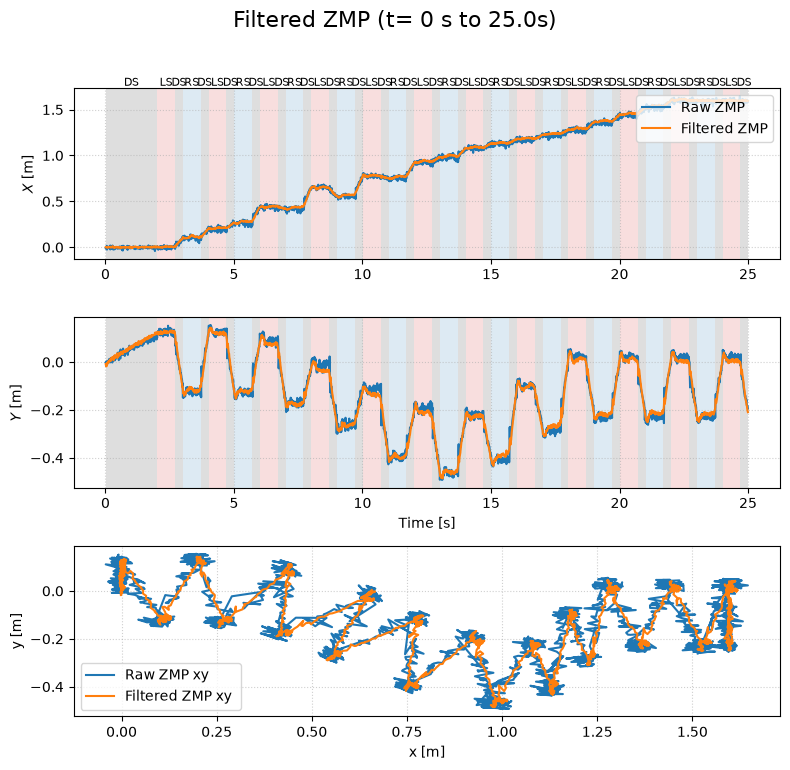

In [ ]:
PlotCoMZMP(
    time_log=time[::100], 
    CoM_data=filtered_ZMP_data[:,::100], 
    ZMP_data=actual_ZMP_data[:,::100], 
    title=f"Filtered ZMP",
    phase_codes=walking_phase[::100], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False,
    labels=["Raw ZMP", "Filtered ZMP"]
)

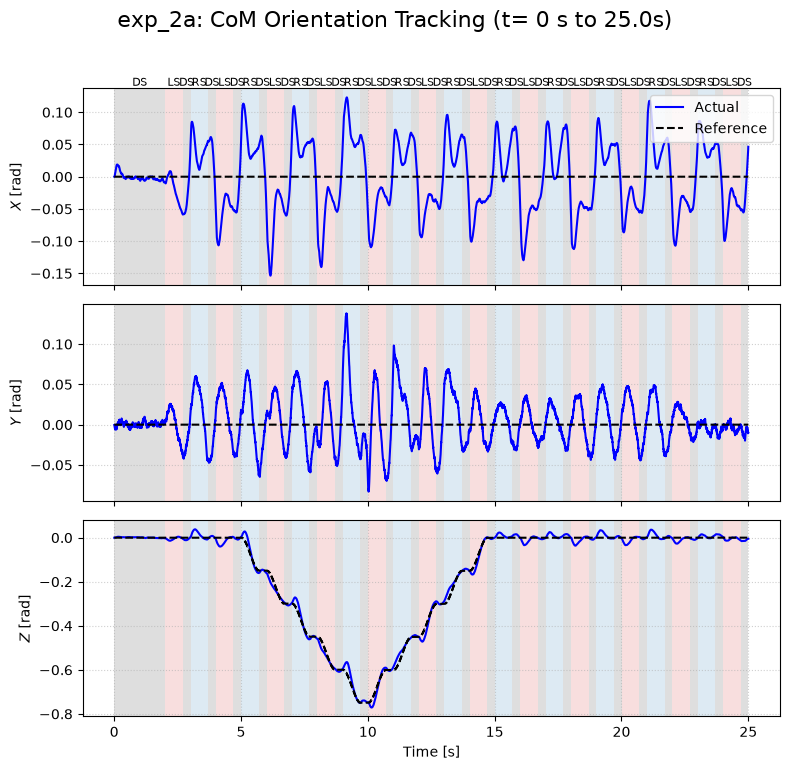

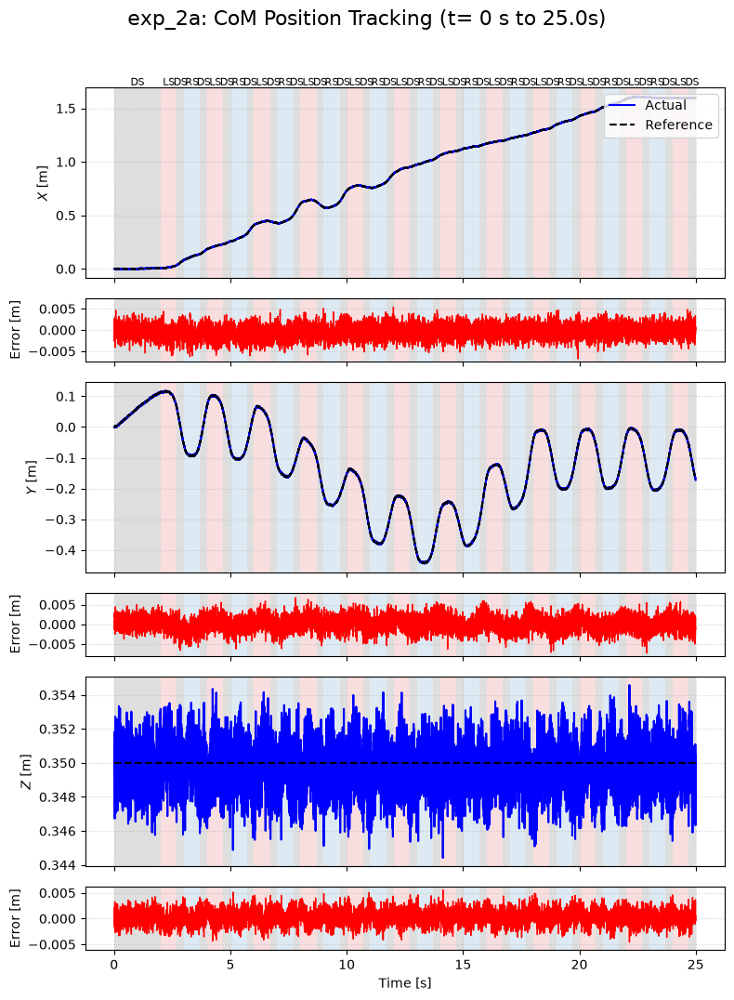

In [ ]:
PlotTracking(
    time_log=time, 
    unit="rad",
    ref_data=desired_CoM_state_data[0:3,:], 
    act_data=actual_CoM_state_data[0:3,:], 
    title=f"{exp_config.exp_name[0:6]}: CoM Orientation Tracking",
    phase_codes=walking_phase, 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False
)
PlotTracking(
    time_log=time[::10], 
    ref_data=desired_CoM_state_data[3:6,::10], 
    act_data=filtered_CoM_state_data[3:6,::10], 
    title=f"{exp_config.exp_name[0:6]}: CoM Position Tracking",
    phase_codes=walking_phase[::10], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=True
)


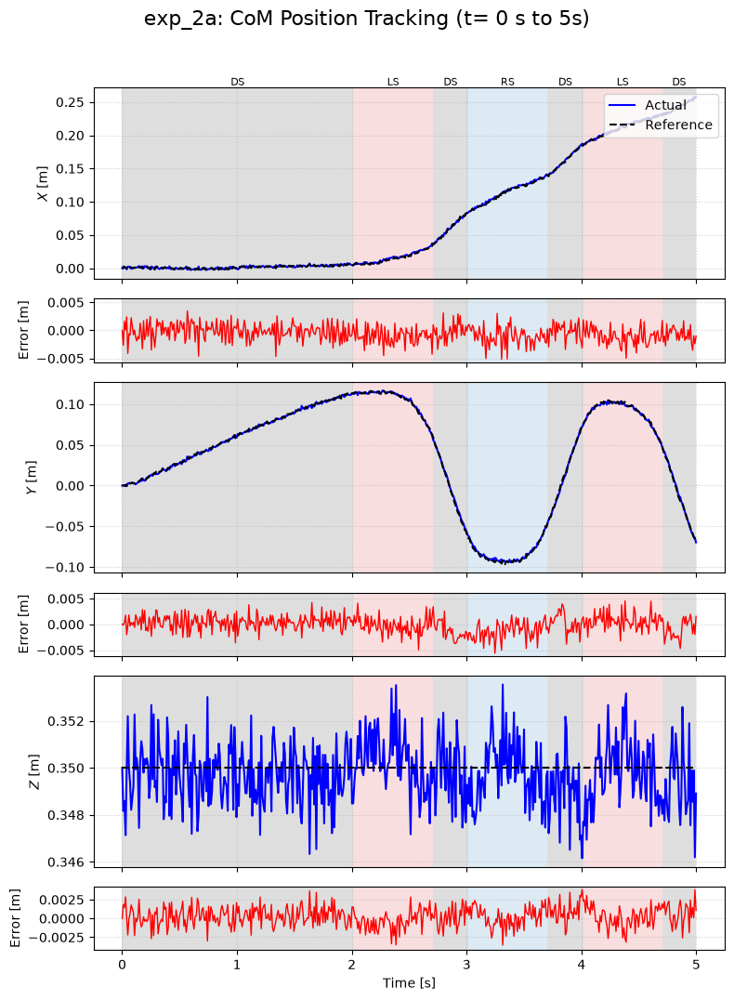

In [ ]:
PlotTracking(
    time_log=time[::100], 
    ref_data=desired_CoM_state_data[3:6,::100], 
    act_data=filtered_CoM_state_data[3:6,::100], 
    title=f"{exp_config.exp_name[0:6]}: CoM Position Tracking",
    phase_codes=walking_phase[::100], 
    plot_interval=(0,5),
    save_folder=save_path,
    show_error=True
)

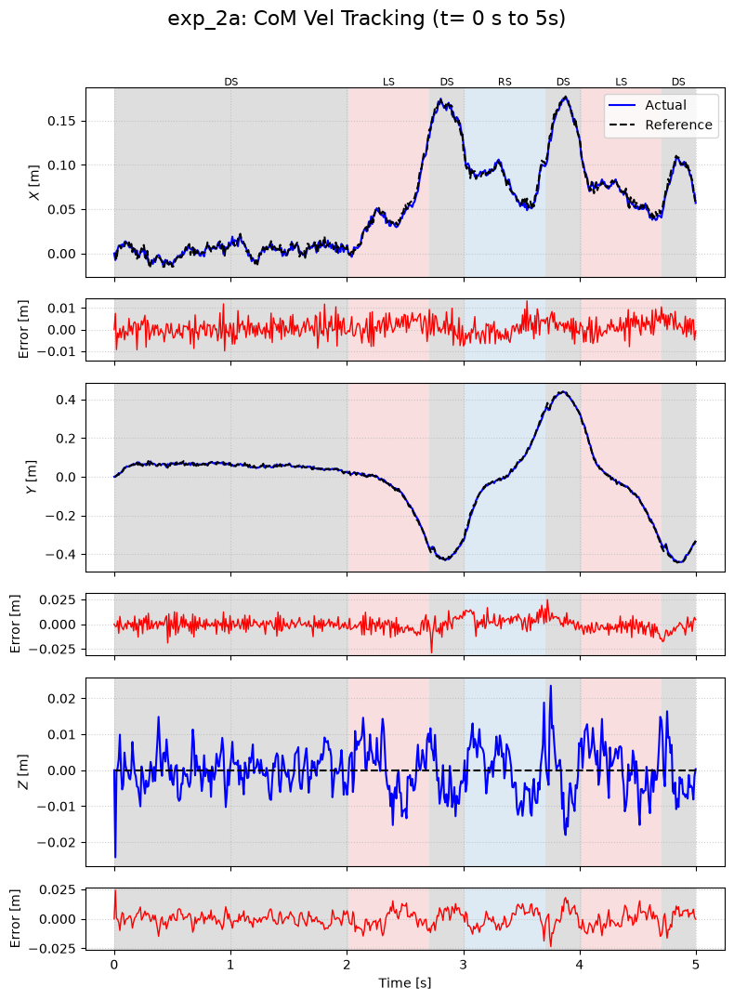

In [ ]:
PlotTracking(
    time_log=time[::100], 
    ref_data=desired_CoM_state_data[9:,::100], 
    act_data=filtered_CoM_state_data[9:,::100], 
    title=f"{exp_config.exp_name[0:6]}: CoM Vel Tracking",
    phase_codes=walking_phase[::100], 
    plot_interval=(0,5),
    save_folder=save_path,
    show_error=True
)

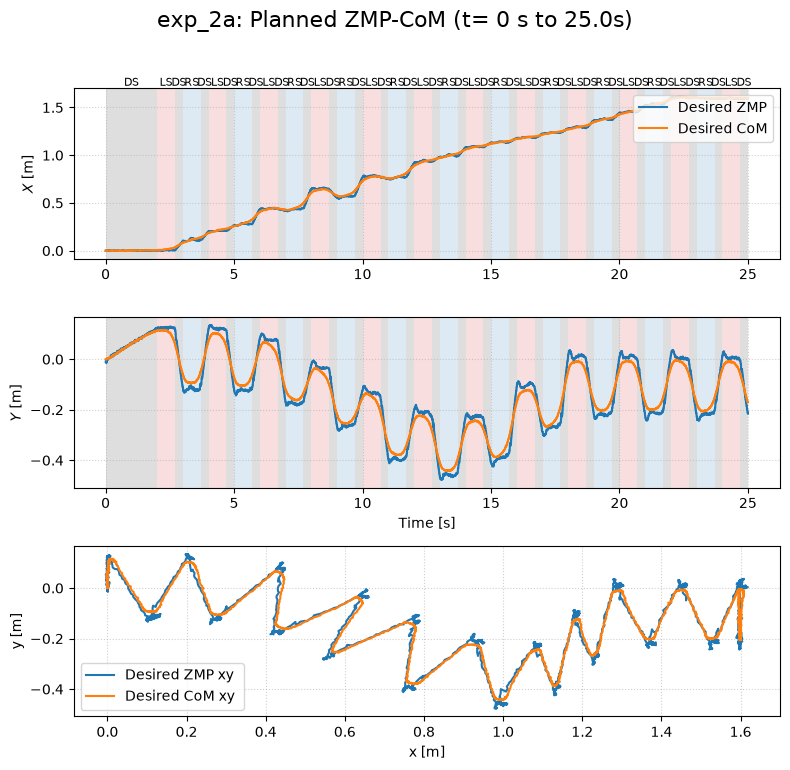

In [ ]:
PlotCoMZMP(
    time_log=time[::10], 
    CoM_data=desired_CoM_state_data[3:6,::10], 
    ZMP_data=desired_zmp_data[0:3,::10], 
    title=f"{exp_config.exp_name[0:6]}: Planned ZMP-CoM",
    phase_codes=walking_phase[::10], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False,
    labels=["Desired ZMP", "Desired CoM"]
)

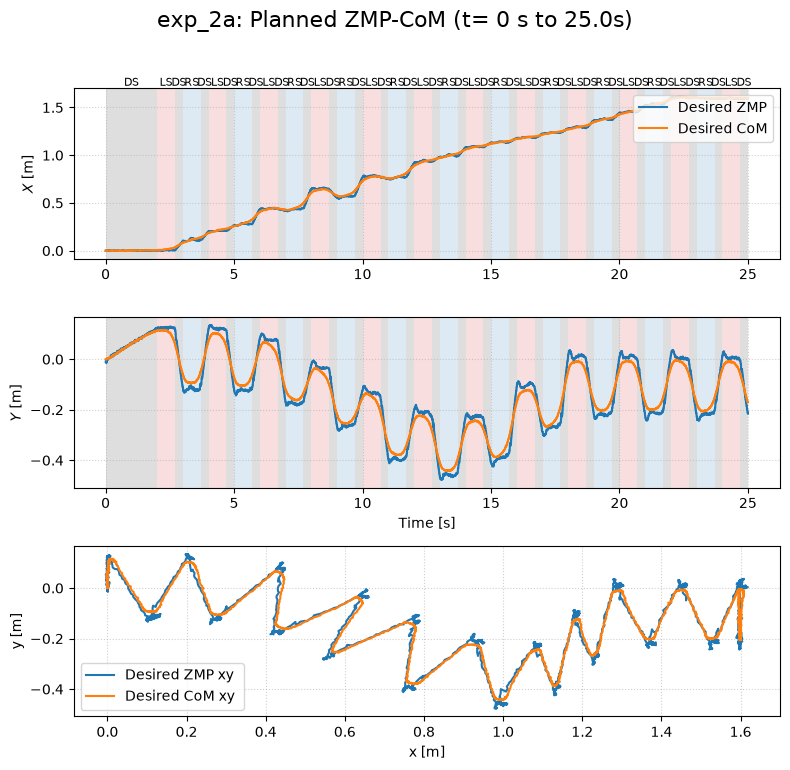

In [ ]:
PlotCoMZMP(
    time_log=time[::10], 
    CoM_data=desired_CoM_state_data[3:6,::10], 
    ZMP_data=desired_zmp_data[0:3,::10], 
    title=f"{exp_config.exp_name[0:6]}: Planned ZMP-CoM",
    phase_codes=walking_phase[::10], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False,
    labels=["Desired ZMP", "Desired CoM"]
)

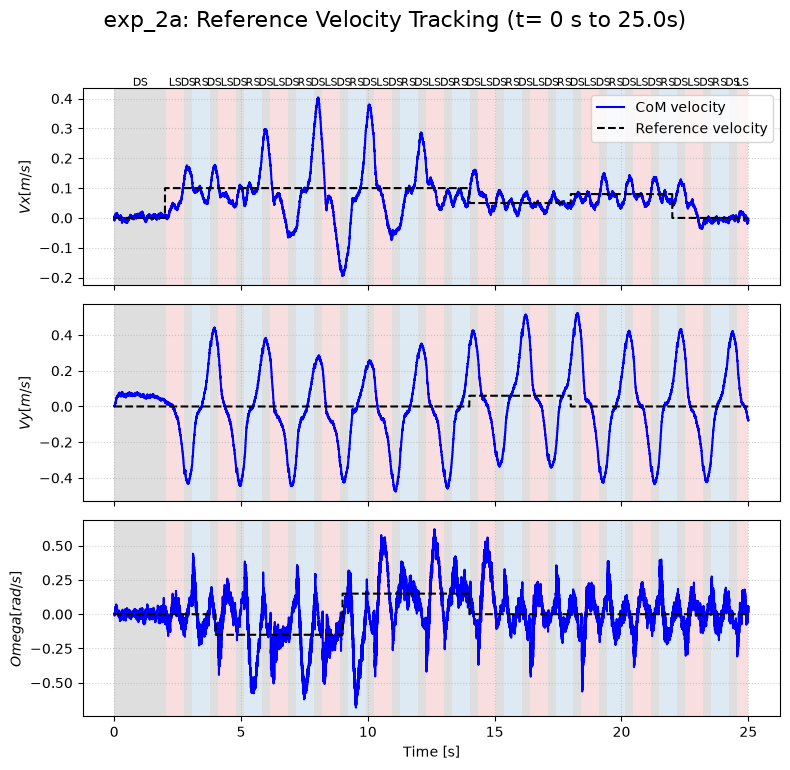

In [ ]:
total_sim_time = simulator.get_mutable_context().get_time()
ts = np.linspace(0, total_sim_time, int(total_sim_time/sim_time_step))
temp_vel = np.array([filtered_CoM_state_data[9,:ts.shape[0]],
                   filtered_CoM_state_data[10,:ts.shape[0]],
                   filtered_CoM_state_data[8,:ts.shape[0]]])
offset = 20000
v_data = np.array([exp_config.VRefCommand(t) for t in ts[0:-offset]])
v_ref = np.hstack((np.ones([3,offset])*0.0 ,v_data.T))
PlotTracking(
    time_log=ts, 
    ref_data=v_ref, 
    dim_labels=["Vx [m/s]", "Vy [m/s]", "Omega [rad/s]"],
    unit=None,
    act_data=temp_vel, 
    title=f"{exp_config.exp_name[0:6]}: Reference Velocity Tracking",
    phase_codes=walking_phase, 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False,
    labels=["CoM velocity", "Reference velocity"]
)

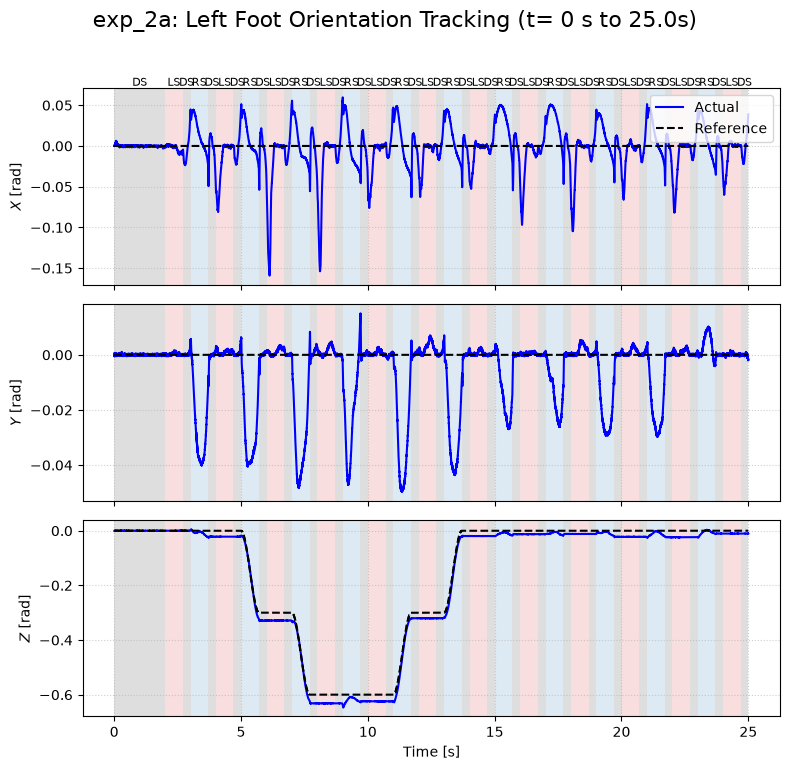

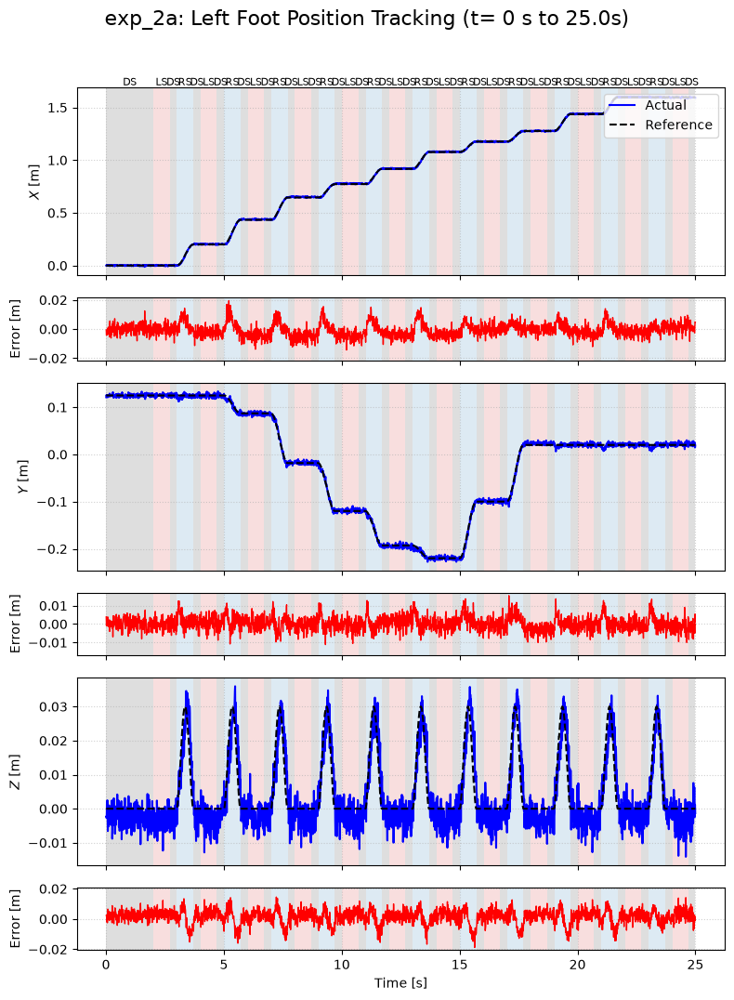

In [ ]:
PlotTracking(
    time_log=time[::10], 
    unit="rad",
    ref_data=desired_lfoot_state_data[0:3,::10], 
    act_data=actual_lfoot_state_data[0:3,::10], 
    title=f"{exp_config.exp_name[0:6]}: Left Foot Orientation Tracking",
    phase_codes=walking_phase[::10], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False
)
PlotTracking(
    time_log=time[::100], 
    ref_data=desired_lfoot_state_data[3:6,::100], 
    act_data=actual_lfoot_state_data[3:6,::100], 
    title=f"{exp_config.exp_name[0:6]}: Left Foot Position Tracking",
    phase_codes=walking_phase[::100], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=True
)

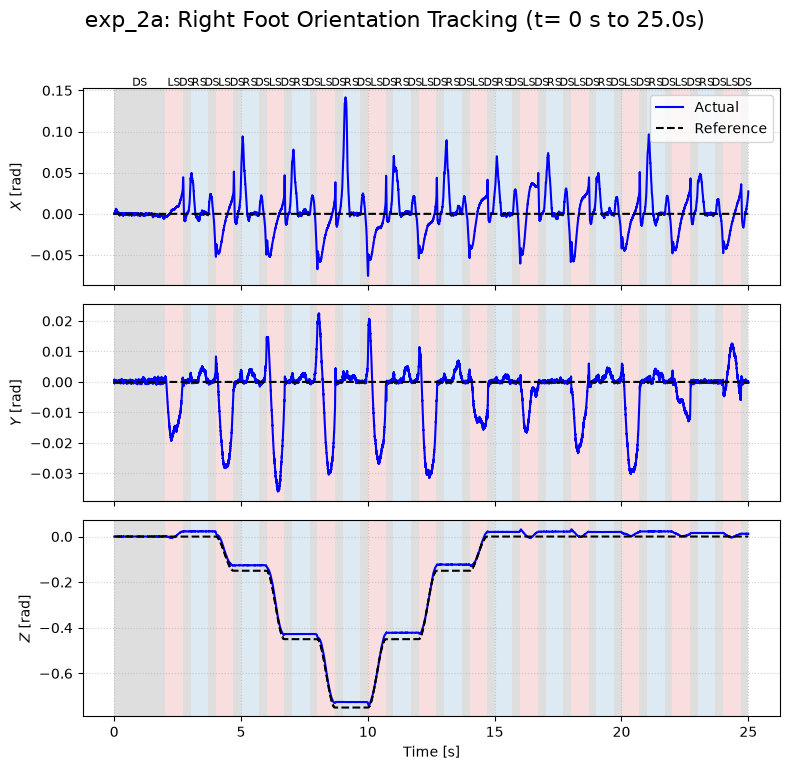

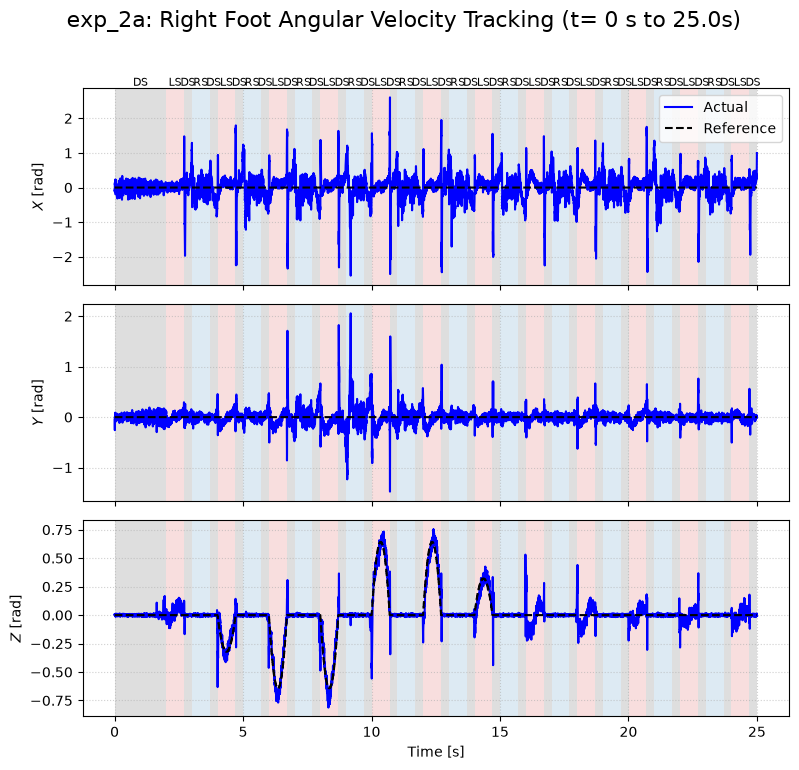

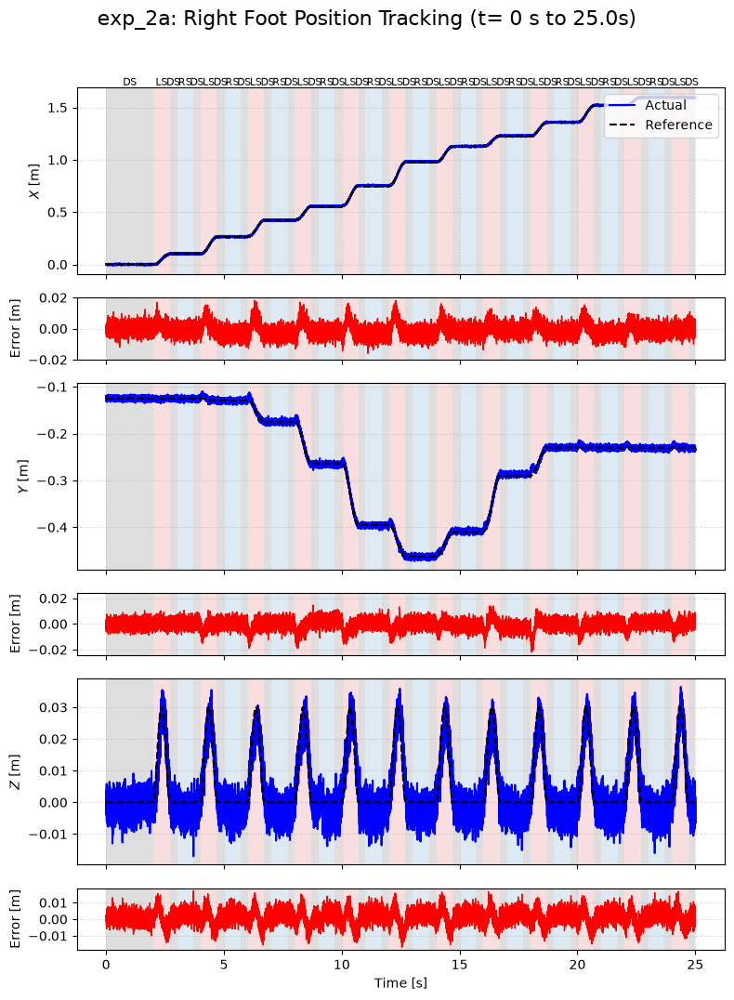

In [ ]:
PlotTracking(
    time_log=time[::10], 
    unit="rad",
    ref_data=desired_rfoot_state_data[0:3,::10], 
    act_data=actual_rfoot_state_data[0:3,::10], 
    title=f"{exp_config.exp_name[0:6]}: Right Foot Orientation Tracking",
    phase_codes=walking_phase[::10], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False
)
PlotTracking(
    time_log=time[::10], 
    unit="rad",
    ref_data=desired_rfoot_state_data[6:9,::10], 
    act_data=actual_rfoot_state_data[6:9,::10], 
    title=f"{exp_config.exp_name[0:6]}: Right Foot Angular Velocity Tracking",
    phase_codes=walking_phase[::10], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False
)
PlotTracking(
    time_log=time[::10], 
    ref_data=desired_rfoot_state_data[3:6,::10], 
    act_data=actual_rfoot_state_data[3:6,::10], 
    title=f"{exp_config.exp_name[0:6]}: Right Foot Position Tracking",
    phase_codes=walking_phase[::10], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=True
)

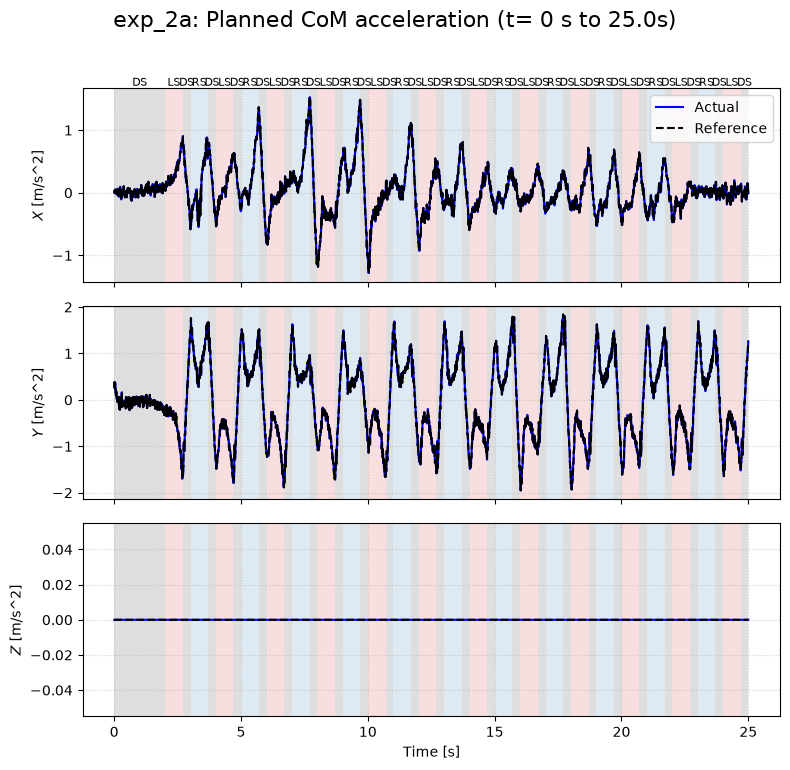

In [ ]:
PlotTracking(
    time_log=time[::10], 
    unit="m/s^2",
    ref_data=desired_CoM_state_data[15:18,::10], 
    act_data=desired_CoM_state_data[15:18,::10], 
    title=f"{exp_config.exp_name[0:6]}: Planned CoM acceleration",
    phase_codes=walking_phase[::10], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False
)

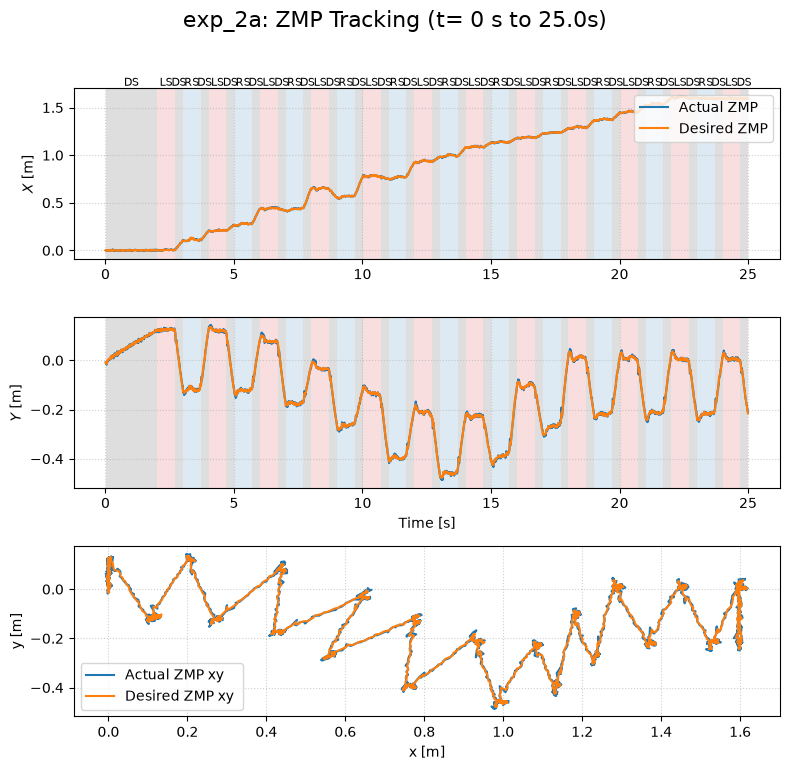

In [ ]:
PlotCoMZMP(
    time_log=time[::100], 
    CoM_data=desired_zmp_data[:, ::100], 
    ZMP_data=filtered_ZMP_data[:, ::100]+0.000, 
    title=f"{exp_config.exp_name[0:6]}: ZMP Tracking",
    phase_codes=walking_phase[::100], 
    plot_interval=plot_interval,
    save_folder=save_path,
    show_error=False,
    labels=["Actual ZMP", "Desired ZMP"]
)

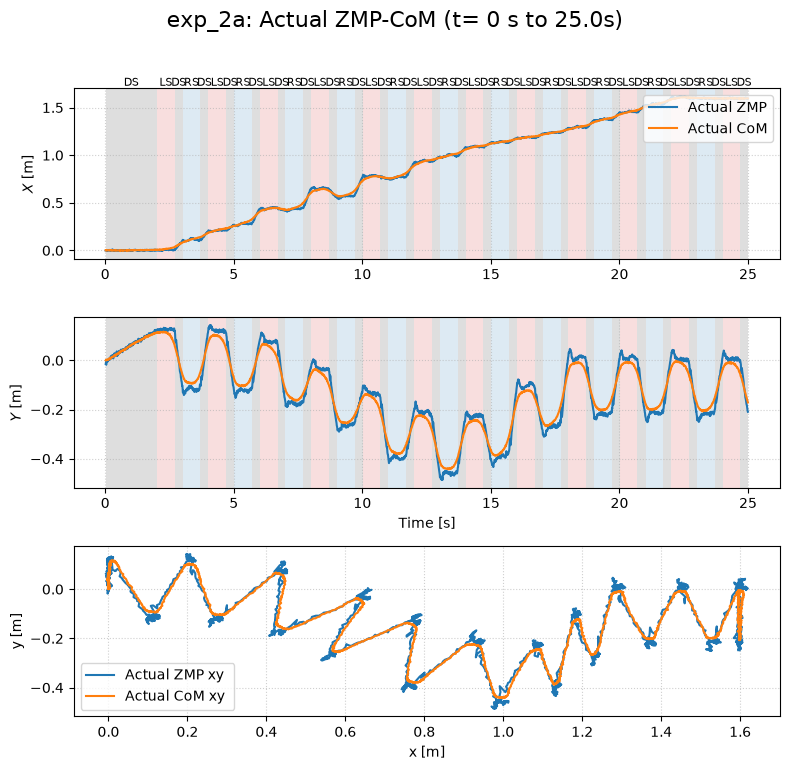

In [ ]:
PlotCoMZMP(
    time_log=time[::100], 
    ZMP_data=filtered_ZMP_data[:, ::100]+0.000, 
    CoM_data=filtered_CoM_state_data[3:6, ::100], 
    title=f"{exp_config.exp_name[0:6]}: Actual ZMP-CoM",
    phase_codes=walking_phase[::100], 
    plot_interval=(0.011, sim_time),
    save_folder=save_path,
    show_error=False,
    labels=["Actual ZMP", "Actual CoM"]
)

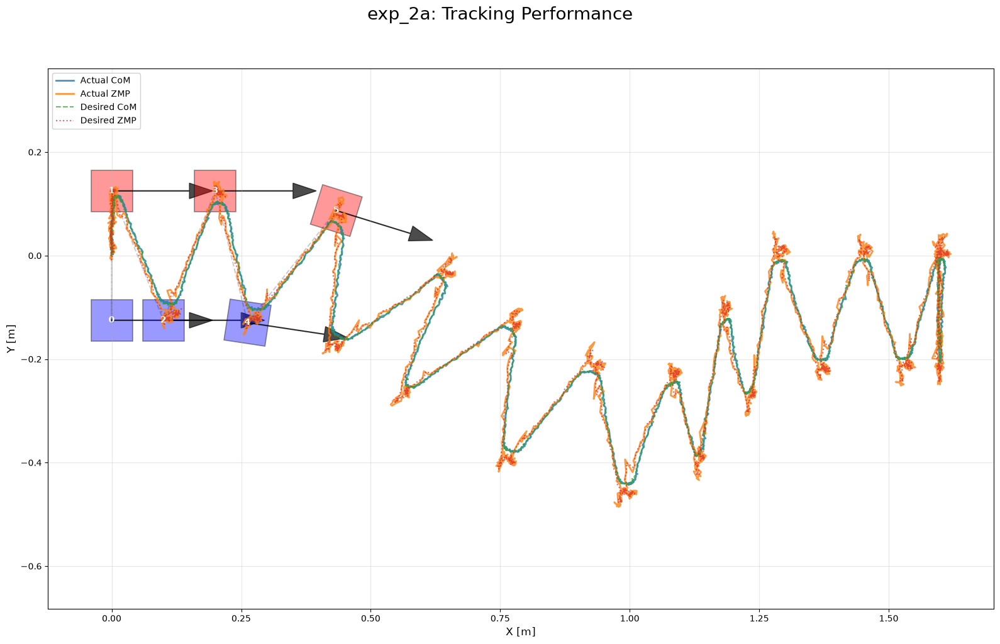

In [ ]:
PlotFootsteps(
    steps=plan[0:6],
    plot_1=[filtered_CoM_state_data[3, 500::100], filtered_CoM_state_data[4, 500::100], "Actual CoM"],
    plot_2=[filtered_ZMP_data[0, 500::100],       filtered_ZMP_data[1, 500::100],       "Actual ZMP"],
    plot_3=[desired_CoM_state_data[3, 500::100],  desired_CoM_state_data[4, 500::100],  "Desired CoM"],
    plot_4=[desired_zmp_data[0, 500::100],        desired_zmp_data[1, 500::100],        "Desired ZMP"],
    save_folder=save_path,
    support_size=[params['foot_size'], params['foot_size']],
    title=f"{exp_config.exp_name[0:6]}: Tracking Performance"
)

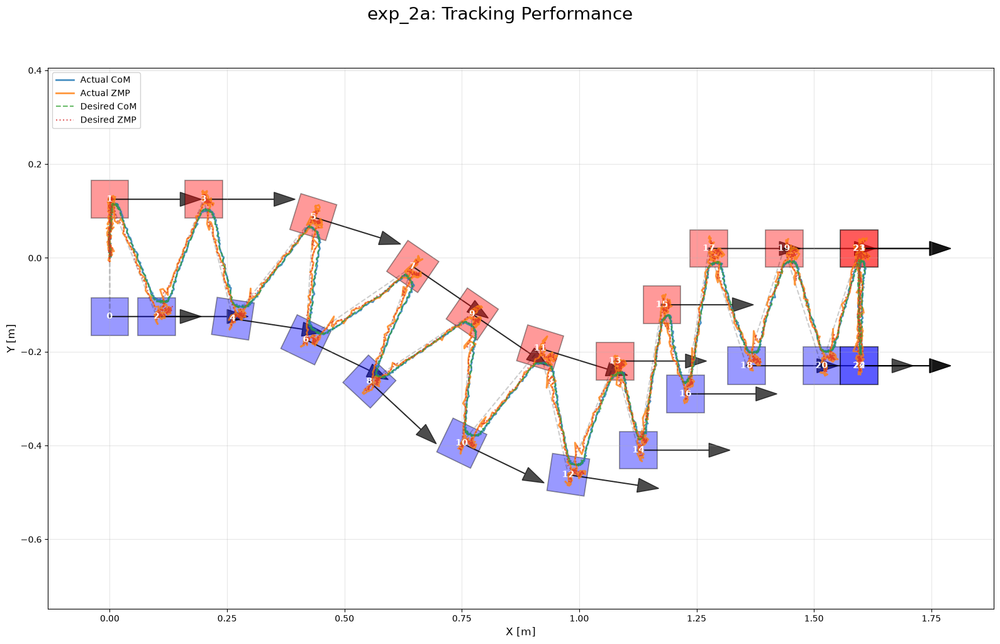

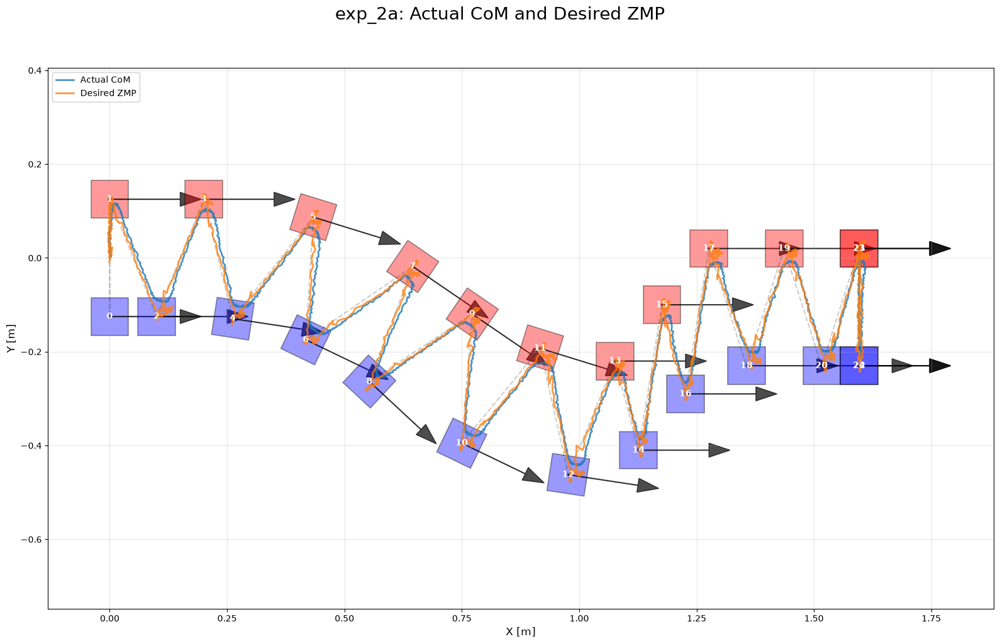

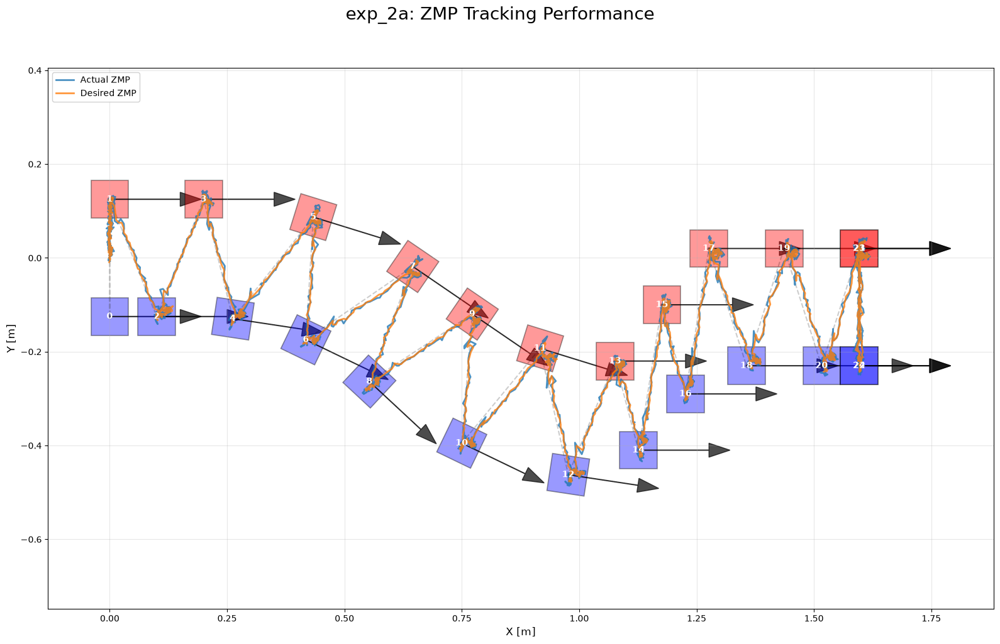

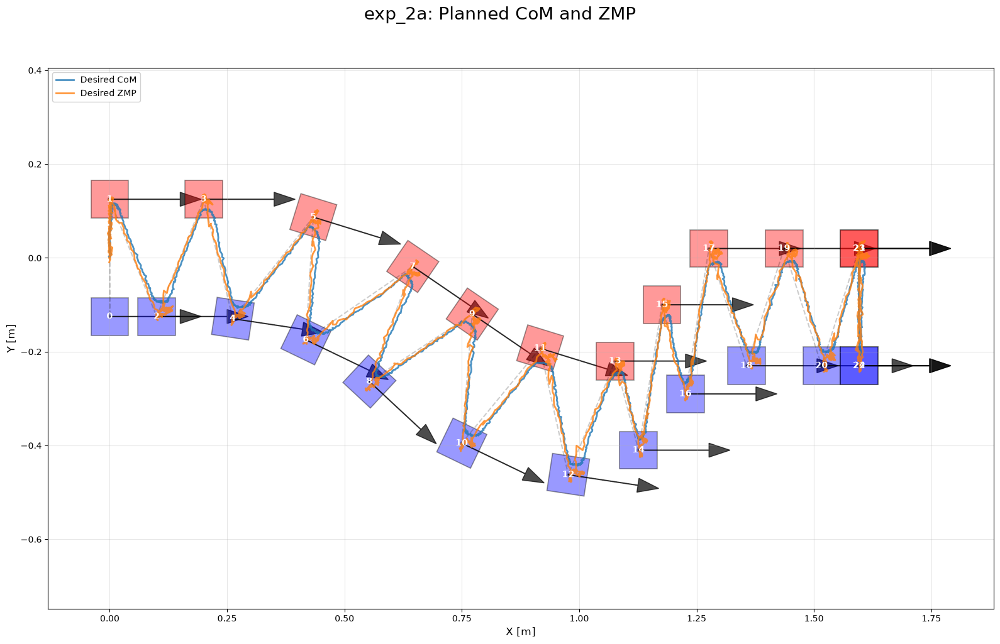

In [ ]:
PlotFootsteps(
    steps=plan,
    plot_1=[filtered_CoM_state_data[3, 500::100], filtered_CoM_state_data[4, 500::100], "Actual CoM"],
    plot_2=[filtered_ZMP_data[0, 500::100],       filtered_ZMP_data[1, 500::100],       "Actual ZMP"],
    plot_3=[desired_CoM_state_data[3, 500::100],  desired_CoM_state_data[4, 500::100],  "Desired CoM"],
    plot_4=[desired_zmp_data[0, 500::100],        desired_zmp_data[1, 500::100],        "Desired ZMP"],
    save_folder=save_path,
    support_size=[params['foot_size'], params['foot_size']],
    title=f"{exp_config.exp_name[0:6]}: Tracking Performance"
)
PlotFootsteps(
    steps=plan,
    plot_2=[desired_zmp_data[0, 500::100],        desired_zmp_data[1, 500::100],        "Desired ZMP"],
    plot_1=[filtered_CoM_state_data[3, 500::100], filtered_CoM_state_data[4, 500::100], "Actual CoM"],
    save_folder=save_path,
    support_size=[params['foot_size'], params['foot_size']],
    title=f"{exp_config.exp_name[0:6]}: Actual CoM and Desired ZMP"
)
PlotFootsteps(
    steps=plan,
    plot_1=[filtered_ZMP_data[0, 500::100], filtered_ZMP_data[1, 500::100], "Actual ZMP"],
    plot_2=[desired_zmp_data[0, 500::100],  desired_zmp_data[1, 500::100],  "Desired ZMP"],
    save_folder=save_path,
    support_size=[params['foot_size'], params['foot_size']],
    title=f"{exp_config.exp_name[0:6]}: ZMP Tracking Performance"
)

PlotFootsteps(
    steps=plan,
    # Plot 1: Desired Center of Mass (Mass trajectory)
    plot_1=[desired_CoM_state_data[3, 500::100], 
            desired_CoM_state_data[4, 500::100], 
            "Desired CoM"],
    
    # Plot 2: Desired Zero Moment Point (Ground pressure reference)
    plot_2=[desired_zmp_data[0, 500::100], 
            desired_zmp_data[1, 500::100], 
            "Desired ZMP"],
    
    save_folder=save_path,
    support_size=[params['foot_size'], params['foot_size']],
    title=f"{exp_config.exp_name[0:6]}: Planned CoM and ZMP"
)

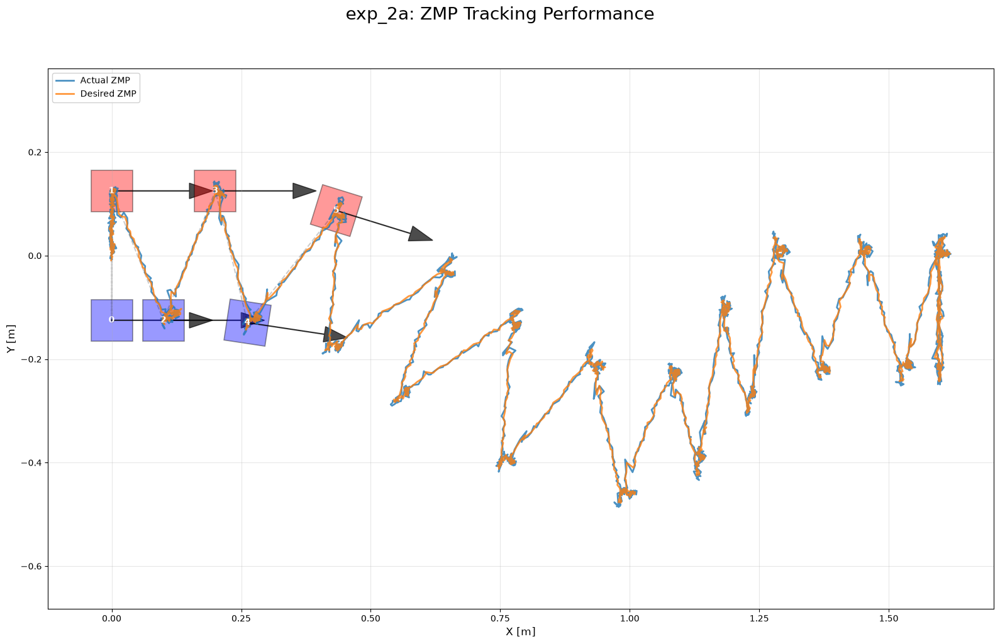

In [ ]:
PlotFootsteps(
    steps=plan[0:6],
    plot_1=[filtered_ZMP_data[0, 500::100], filtered_ZMP_data[1, 500::100], "Actual ZMP"],
    plot_2=[desired_zmp_data[0, 500::100],  desired_zmp_data[1, 500::100],  "Desired ZMP"],
    save_folder=save_path,
    support_size=[params['foot_size'], params['foot_size']],
    title=f"{exp_config.exp_name[0:6]}: ZMP Tracking Performance"
)

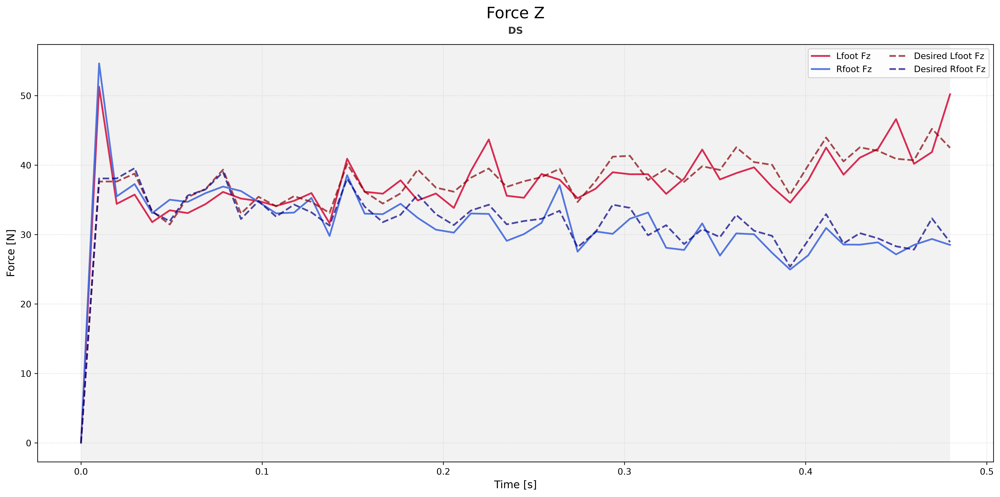

In [ ]:
PlotGRF(
    time_data     = time[::100],
    walking_phase = walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [GRF_data[5,::100],   "Lfoot Fz"],
    plot_2 = [GRF_data[11,::100], "Rfoot Fz"],
    plot_3 = [desired_foot_wrenchs_data[5,::100],   "Desired Lfoot Fz"],
    plot_4 = [desired_foot_wrenchs_data[11,::100], "Desired Rfoot Fz"],
    
    plot_interval = [0,0.5], # Plots the full duration
    title         = "Force Z",
    ylabel        = "Force [N]"
)

In [ ]:
temp_L = desired_foot_wrenchs_data[5,::100]
temp_R = desired_foot_wrenchs_data[11,::100]
folder_name = f"{RESULT_ROOT}/Final/Data/Fz_with_ref.npz"
np.savez_compressed(folder_name,
                    timestamp   = time,
                    Fz_L        = temp_L,
                    Fz_R        = temp_R)

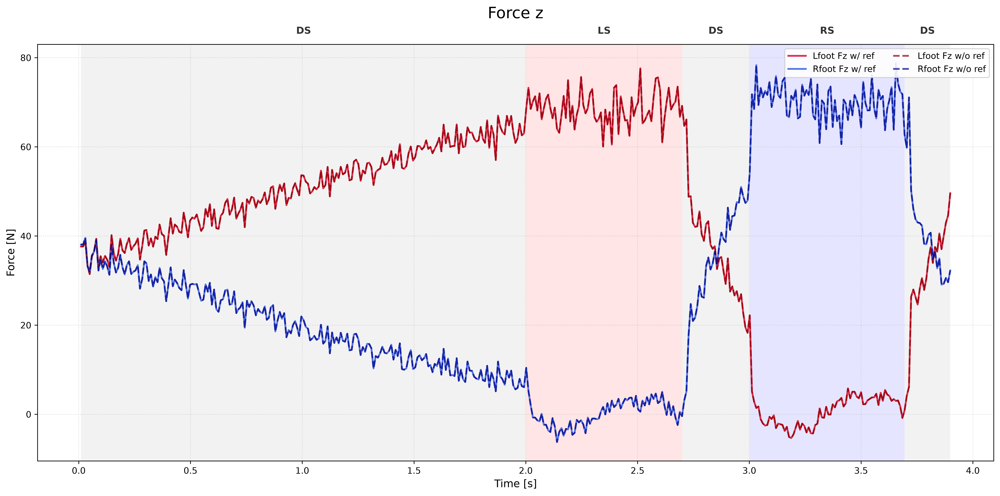

In [ ]:
PlotGRF(
    time_data     = time[::100],
    walking_phase = walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [temp_L,   "Lfoot Fz w/ ref"],
    plot_2 = [temp_R, "Rfoot Fz w/ ref"],
    plot_3 = [desired_foot_wrenchs_data[5,::100],   "Lfoot Fz w/o ref"],
    plot_4 = [desired_foot_wrenchs_data[11,::100], "Rfoot Fz w/o ref"],
    
    plot_interval = [0.01,4], # Plots the full duration
    title         = "Force z",
    ylabel        = "Force [N]"
)

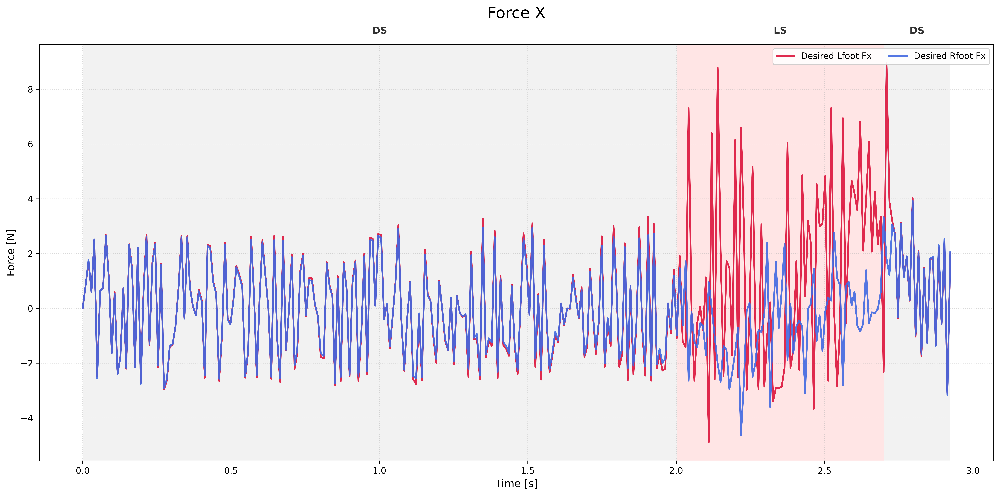

In [ ]:
PlotGRF(
    time_data     = time[::100],
    walking_phase = walking_phase[::100],
    
    # Passing the Fz components (Index 5 for Left, 11 for Right)
    plot_1 = [desired_foot_wrenchs_data[3,::100],   "Desired Lfoot Fx"],
    plot_2 = [desired_foot_wrenchs_data[9,::100], "Desired Rfoot Fx"],
    # plot_3 = [desired_foot_wrenchs_data[4,::100],   "Desired Lfoot Fy"],
    # plot_4 = [desired_foot_wrenchs_data[10,::100], "Desired Rfoot Fy"],
    
    plot_interval = [0,3], # Plots the full duration
    title         = "Force X",
    ylabel        = "Force [N]"
)

### Backyard

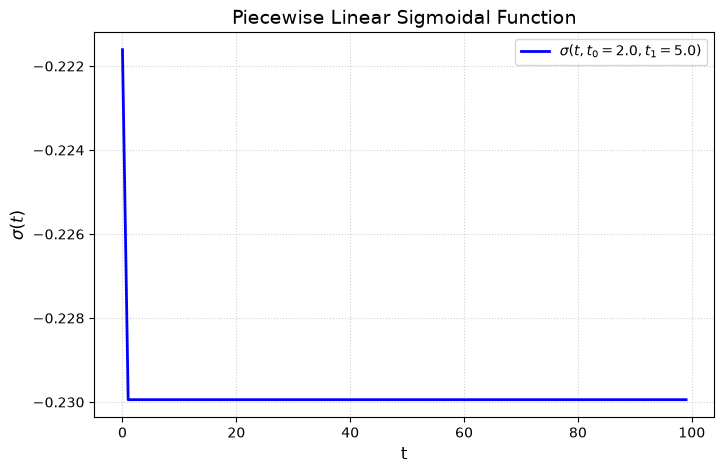

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function
sigma = lambda t, t0, t1: np.clip((t - t0) / (t1 - t0), 0, 1)

# Parameters for the plot
t0 = 2.0
t1 = 5.0
t = np.linspace(0, 7, 500)
y = sigma(t, t0, t1)

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(gait_planner.mpc.mc_y, label=rf'$\sigma(t, t_0={t0}, t_1={t1})$', linewidth=2, color='blue')

# Marking the transition points
# plt.axvline(t0, color='red', linestyle='--', alpha=0.5, label=f'$t_0 = {t0}$')
# plt.axvline(t1, color='green', linestyle='--', alpha=0.5, label=f'$t_1 = {t1}$')

plt.title('Piecewise Linear Sigmoidal Function', fontsize=14)
plt.xlabel('t', fontsize=12)
plt.ylabel(r'$\sigma(t)$', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
# plt.ylim(-1.1, 1.1)

plt.savefig('sigma_plot.png', dpi=300, bbox_inches='tight')

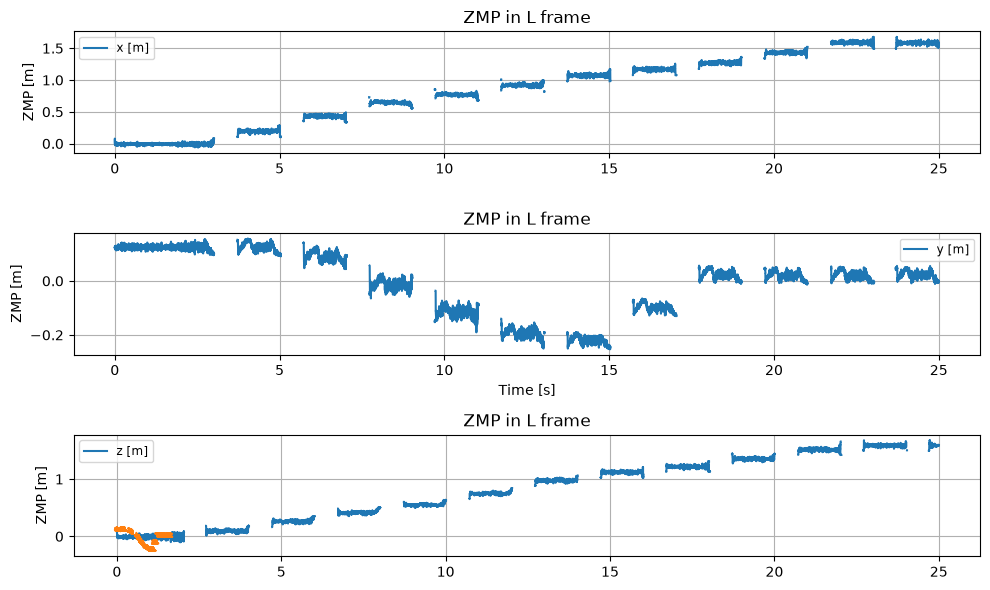

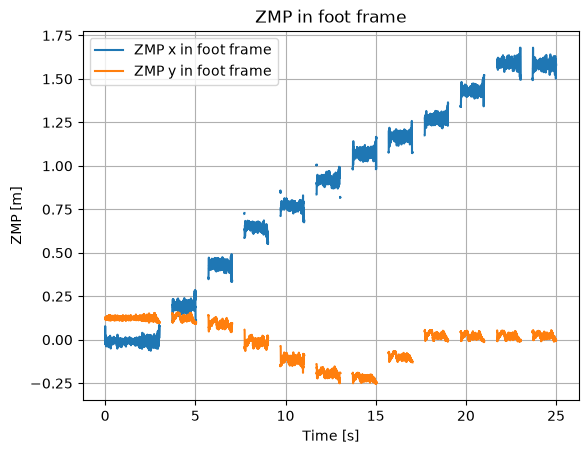

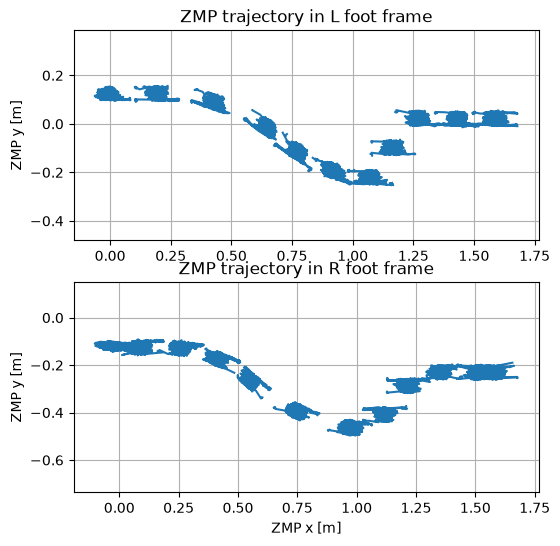

In [ ]:
time_zmp_foot = ZMP_in_foot_frame_log.sample_times()
zmp_foot_data = ZMP_in_foot_frame_data

fig, axs = plt.subplots(3, 1, figsize=(10, 6))
foot_labels = ["Left foot", "Right foot"]
coord_labels = ["x [m]", "y [m]", "z [m]"]

for foot_idx, ax in enumerate(axs):
    ax.plot(time_zmp_foot, zmp_foot_data[foot_idx, :],
            label=f"{coord_labels[foot_idx]}")
    ax.set_title(f"ZMP in L frame")
    ax.set_ylabel("ZMP [m]")
    ax.legend(fontsize="small")
    ax.grid(True)
axs[2].plot(zmp_foot_data[0, :], zmp_foot_data[1, :],label=f"ZMP L xy")
axs[2].grid(True)

axs[-2].set_xlabel("Time [s]")
plt.tight_layout()
plt.show()

plt.plot(time,zmp_foot_data[0, :], label="ZMP x in foot frame")
plt.plot(time,zmp_foot_data[1, :], label="ZMP y in foot frame")
plt.xlabel("Time [s]")
plt.ylabel("ZMP [m]")
plt.title("ZMP in foot frame")
plt.legend()
plt.grid()
plt.show()

fig, axs = plt.subplots(2, 1, figsize=(6, 6))
start = int(0.05 * 10000)
stop = int(sim_time * 10000)
axs[0].plot(zmp_foot_data[0, start:stop], zmp_foot_data[1, start:stop],label=f"ZMP L xy")
# axs[0].set_xlabel("ZMP x [m]")
axs[0].set_ylabel("ZMP y [m]")
axs[0].set_title("ZMP trajectory in L foot frame")
ax.legend(fontsize="small")
axs[0].grid(True)
axs[0].axis("equal")

axs[1].plot(zmp_foot_data[2, start:stop], zmp_foot_data[3, start:stop],label=f"ZMP R xy")
axs[1].set_xlabel("ZMP x [m]")
axs[1].set_ylabel("ZMP y [m]")
axs[1].set_title("ZMP trajectory in R foot frame")
ax.legend(fontsize="small")
axs[1].grid(True)
axs[1].axis("equal")
plt.show()

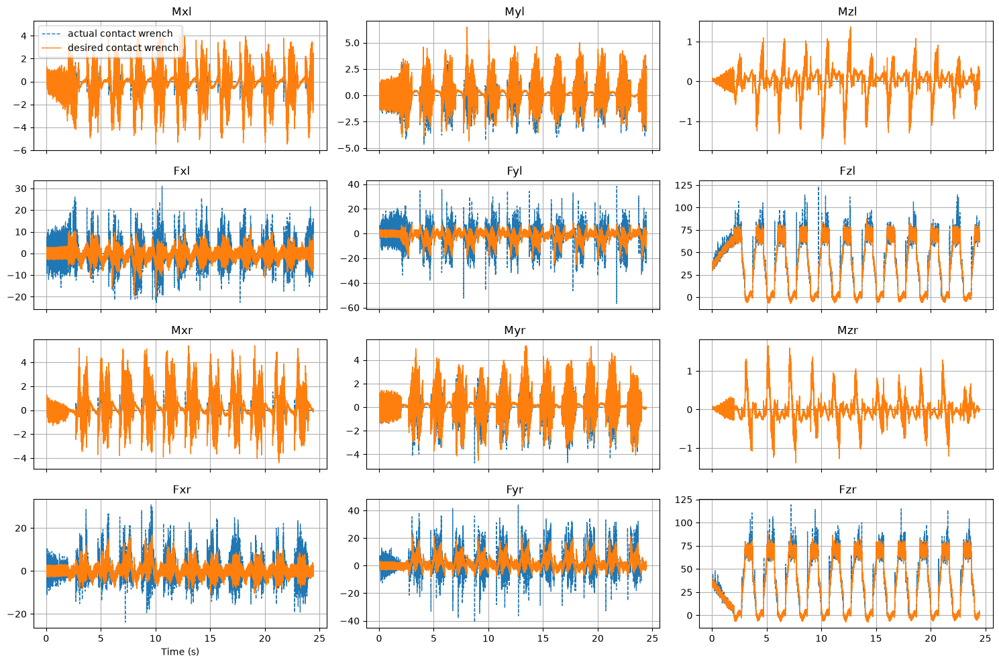

In [ ]:

fig, axs = plt.subplots(4, 3, figsize=(15, 10), sharex=True)
titles = ['Mxl', 'Myl', 'Mzl', 'Fxl', 'Fyl', 'Fzl', 'Mxr', 'Myr', 'Mzr', 'Fxr', 'Fyr', 'Fzr']
for i, ax in enumerate(axs.flat):
    # ax.plot(time[start:stop], total_contact_wrenches_data[i, start:stop], label='actual contact wrench', linestyle='--', linewidth=1)
    ax.plot(time[start:stop], GRF_data[i, start:stop], label='actual contact wrench', linestyle='--', linewidth=1)
    ax.plot(time[start:stop], desired_foot_wrenchs_data[i, start:stop], label='desired contact wrench', linewidth=1)
    ax.set_title(f' {titles[i]}')
    ax.grid(True)
    if i == 0:
        ax.legend()

axs[-1, 0].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

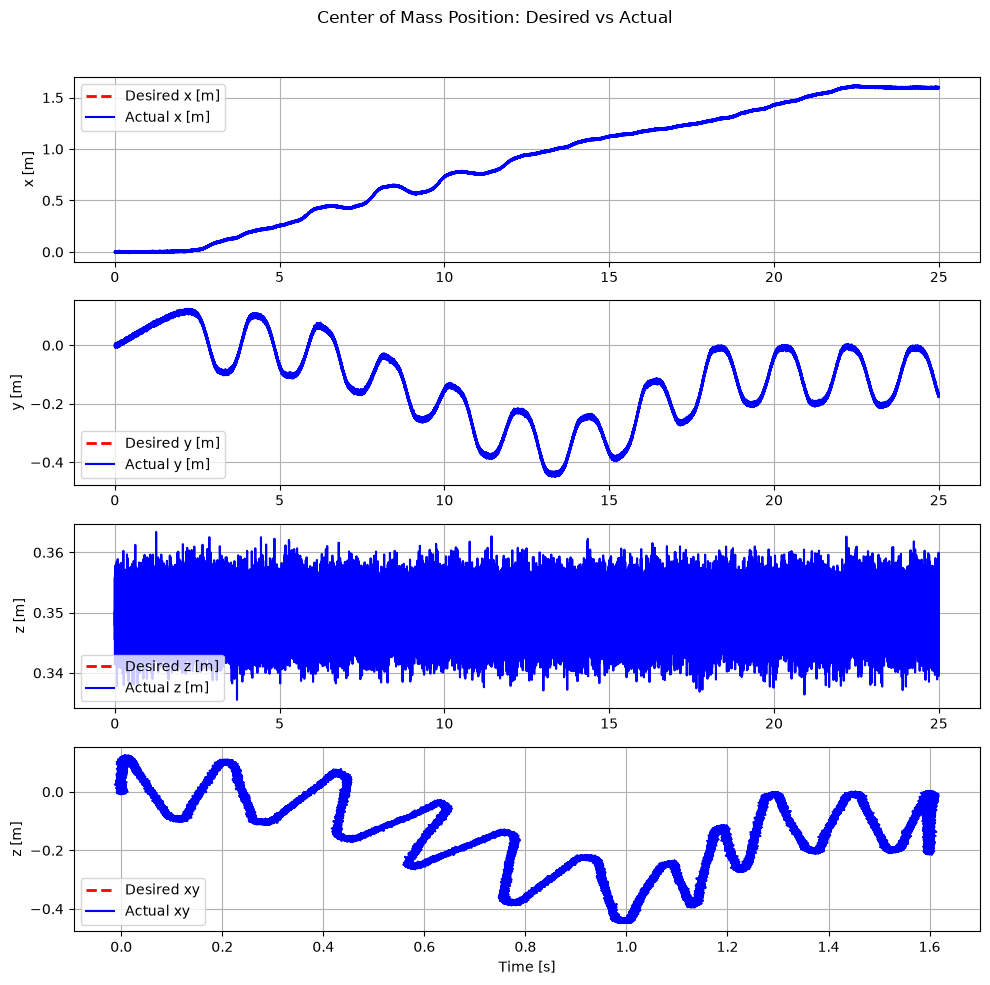

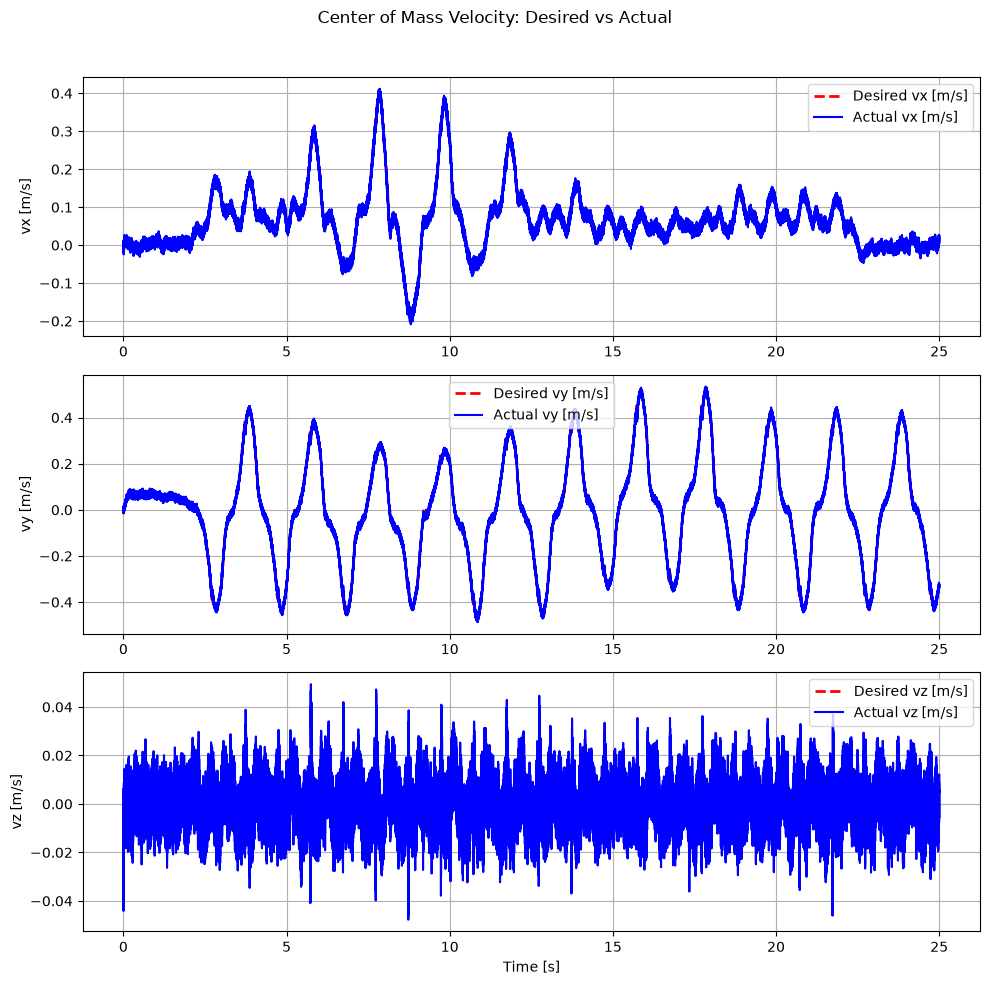

In [ ]:
# Compare Desired vs Actual COM Position and Velocity
time_COM = COM_traj_log.sample_times()
desired_COM_pos = desired_CoM_state_data[3:6, :]  # position from gait planner
desired_COM_vel = desired_CoM_state_data[9:12, :]  # velocity from gait planner
actual_COM_pos = actual_CoM_state_data[3:6, :]  # position from taskspace feedback
actual_COM_vel = actual_CoM_state_data[9:12, :]  # velocity from taskspace feedback

# COM Position Comparison
fig, axs = plt.subplots(4, 1, figsize=(10, 10))
labels = ["x [m]", "y [m]", "z [m]"]
for i in range(3):
    axs[i].plot(time_COM, desired_COM_pos[i, :], label=f'Desired {labels[i]}', linestyle='--', color='red', linewidth=2)
    axs[i].plot(time, actual_COM_pos[i, :], label=f'Actual {labels[i]}', color='blue')
    axs[i].set_ylabel(labels[i])
    axs[i].grid(True)
    axs[i].legend()
axs[3].plot(desired_COM_pos[0, :], desired_COM_pos[1, :], label=f'Desired xy', linestyle='--', color='red', linewidth=2)
axs[3].plot( actual_COM_pos[0, :], actual_COM_pos[1, :], label=f'Actual xy', color='blue')
axs[3].set_ylabel(labels[i])
axs[3].grid(True)
axs[3].legend()
axs[-1].set_xlabel("Time [s]")
plt.suptitle("Center of Mass Position: Desired vs Actual")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# COM Velocity Comparison
fig, axs = plt.subplots(3, 1, figsize=(10, 10))
labels = ["vx [m/s]", "vy [m/s]", "vz [m/s]"]
for i in range(3):
    axs[i].plot(time_COM, desired_COM_vel[i, :], label=f'Desired {labels[i]}', linestyle='--', color='red', linewidth=2)
    axs[i].plot(time, actual_COM_vel[i, :], label=f'Actual {labels[i]}', color='blue')
    axs[i].set_ylabel(labels[i])
    axs[i].grid(True)
    axs[i].legend()
axs[-1].set_xlabel("Time [s]")
plt.suptitle("Center of Mass Velocity: Desired vs Actual")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


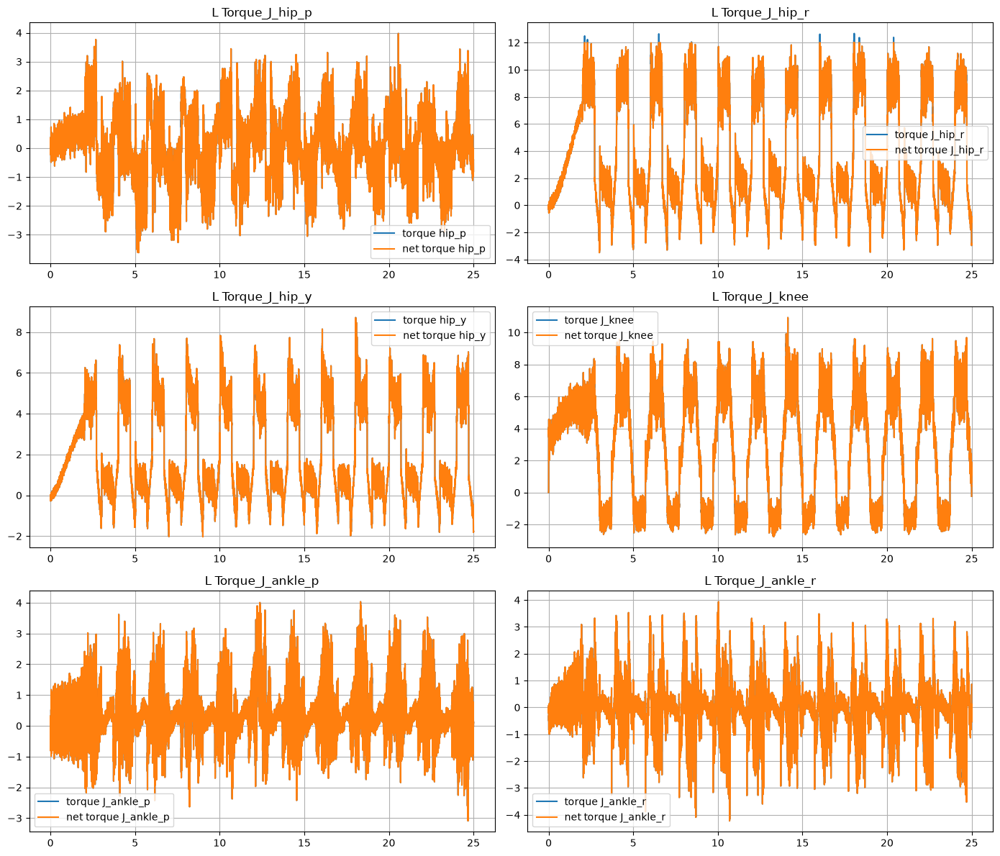

In [ ]:
name = ["J_hip_p","J_hip_r","J_hip_y","J_knee","J_ankle_p","J_ankle_r"]
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
start = 0
stop = len(time) #- 3000
# stop = 13500
for i in range(6):
    temp = name[i]
    ax = axs[i // 2, i % 2]
    if i == 2:
        ax.plot(time[start:stop], torque_command_log.data()[0, start:stop], label="torque hip_y")
        ax.plot(time[start:stop], net_torque_data[0, start:stop], label="net torque hip_y")
    elif i==0:
        ax.plot(time[start:stop], torque_command_log.data()[2, start:stop], label="torque hip_p")
        ax.plot(time[start:stop], net_torque_data[2, start:stop], label="net torque hip_p")
    else:
        ax.plot(time[start:stop], torque_command_log.data()[i, start:stop], label=f"torque {temp}")
        ax.plot(time[start:stop], net_torque_data[i, start:stop], label=f"net torque {temp}")
    # if controller_enable:
    #     ax.plot(time, q_err_log.data()[i, :], label="L Joint error", color="green")

    ax.set_title(f"L Torque_{temp}")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()

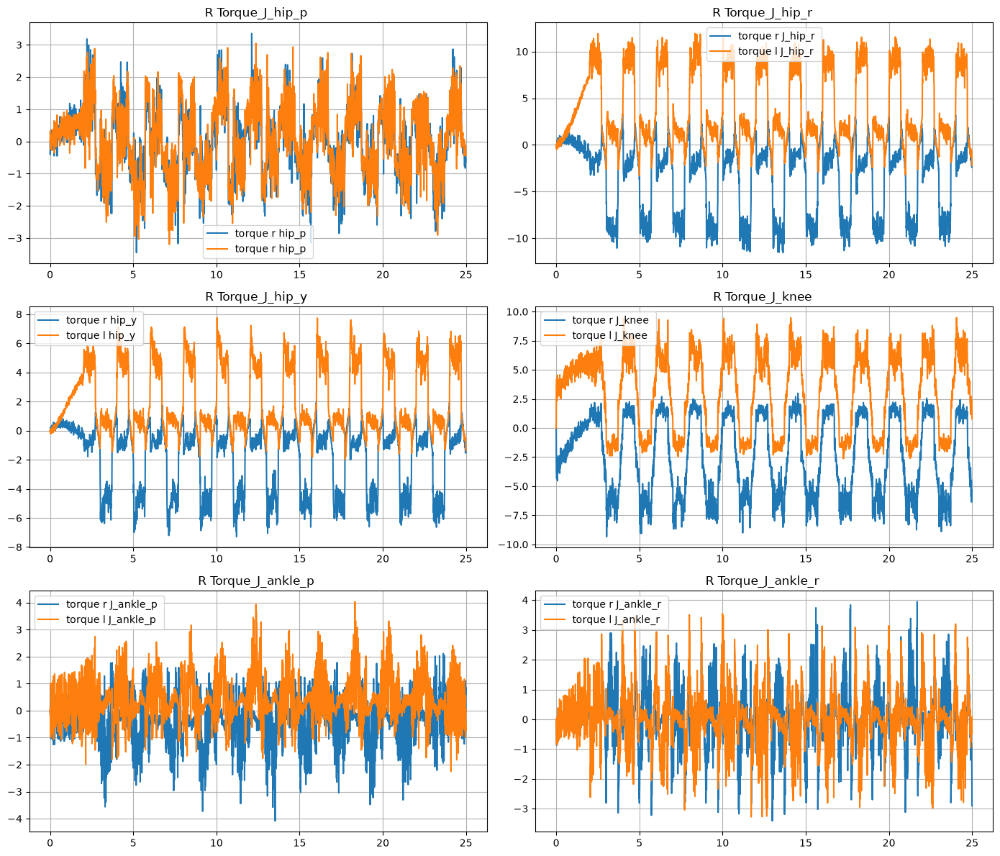

In [ ]:
name = ["J_hip_p","J_hip_r","J_hip_y","J_knee","J_ankle_p","J_ankle_r"]
fig, axs = plt.subplots(3, 2, figsize=(14, 12))
for i in range(6):
    temp = name[i]
    ax = axs[i // 2, i % 2]
    i+=6
    if i == 8:
        ax.plot(time[::100], torque_command_log.data()[6, ::100], label="torque r hip_y ")
        ax.plot(time[::100], torque_command_log.data()[0, ::100], label="torque l hip_y")
    elif i==6:
        ax.plot(time[::100], torque_command_log.data()[8, ::100], label="torque r hip_p ")
        ax.plot(time[::100], torque_command_log.data()[2, ::100], label="torque r hip_p")
    else:
        ax.plot(time[::100], torque_command_log.data()[i, ::100], label=f"torque r {temp} ")
        ax.plot(time[::100], torque_command_log.data()[i-6, ::100], label=f"torque l {temp}")
    # if controller_enable:
    #     ax.plot(time, q_err_log.data()[i, :], label="L Joint error", color="green")

    ax.set_title(f"R Torque_{temp} ")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()